<center>
<br><br><br><br>
<font size="4"><b>Tarea 3 - Componente práctico - Práctica simulada</b></font>
<br><br><br><br>
Estudiante: Ximena Del Pilar Repizo Tovar
<br><br><br><br>
Tutor: Marco Fidel Pechené Rodríguez
<br><br><br><br>
Curso: Programación para el análisis de datos
<br><br><br><br>
Código: 203008069_30
<br><br><br><br>
Universidad Nacional Abierta y a Distancia - UNAD<br><br>
Escuela de Ciencias Básicas Tecnología e Ingeniería<br><br>
Especialización en Ciencia de Datos y Analítica<br><br>
2026<br><br><br><br>

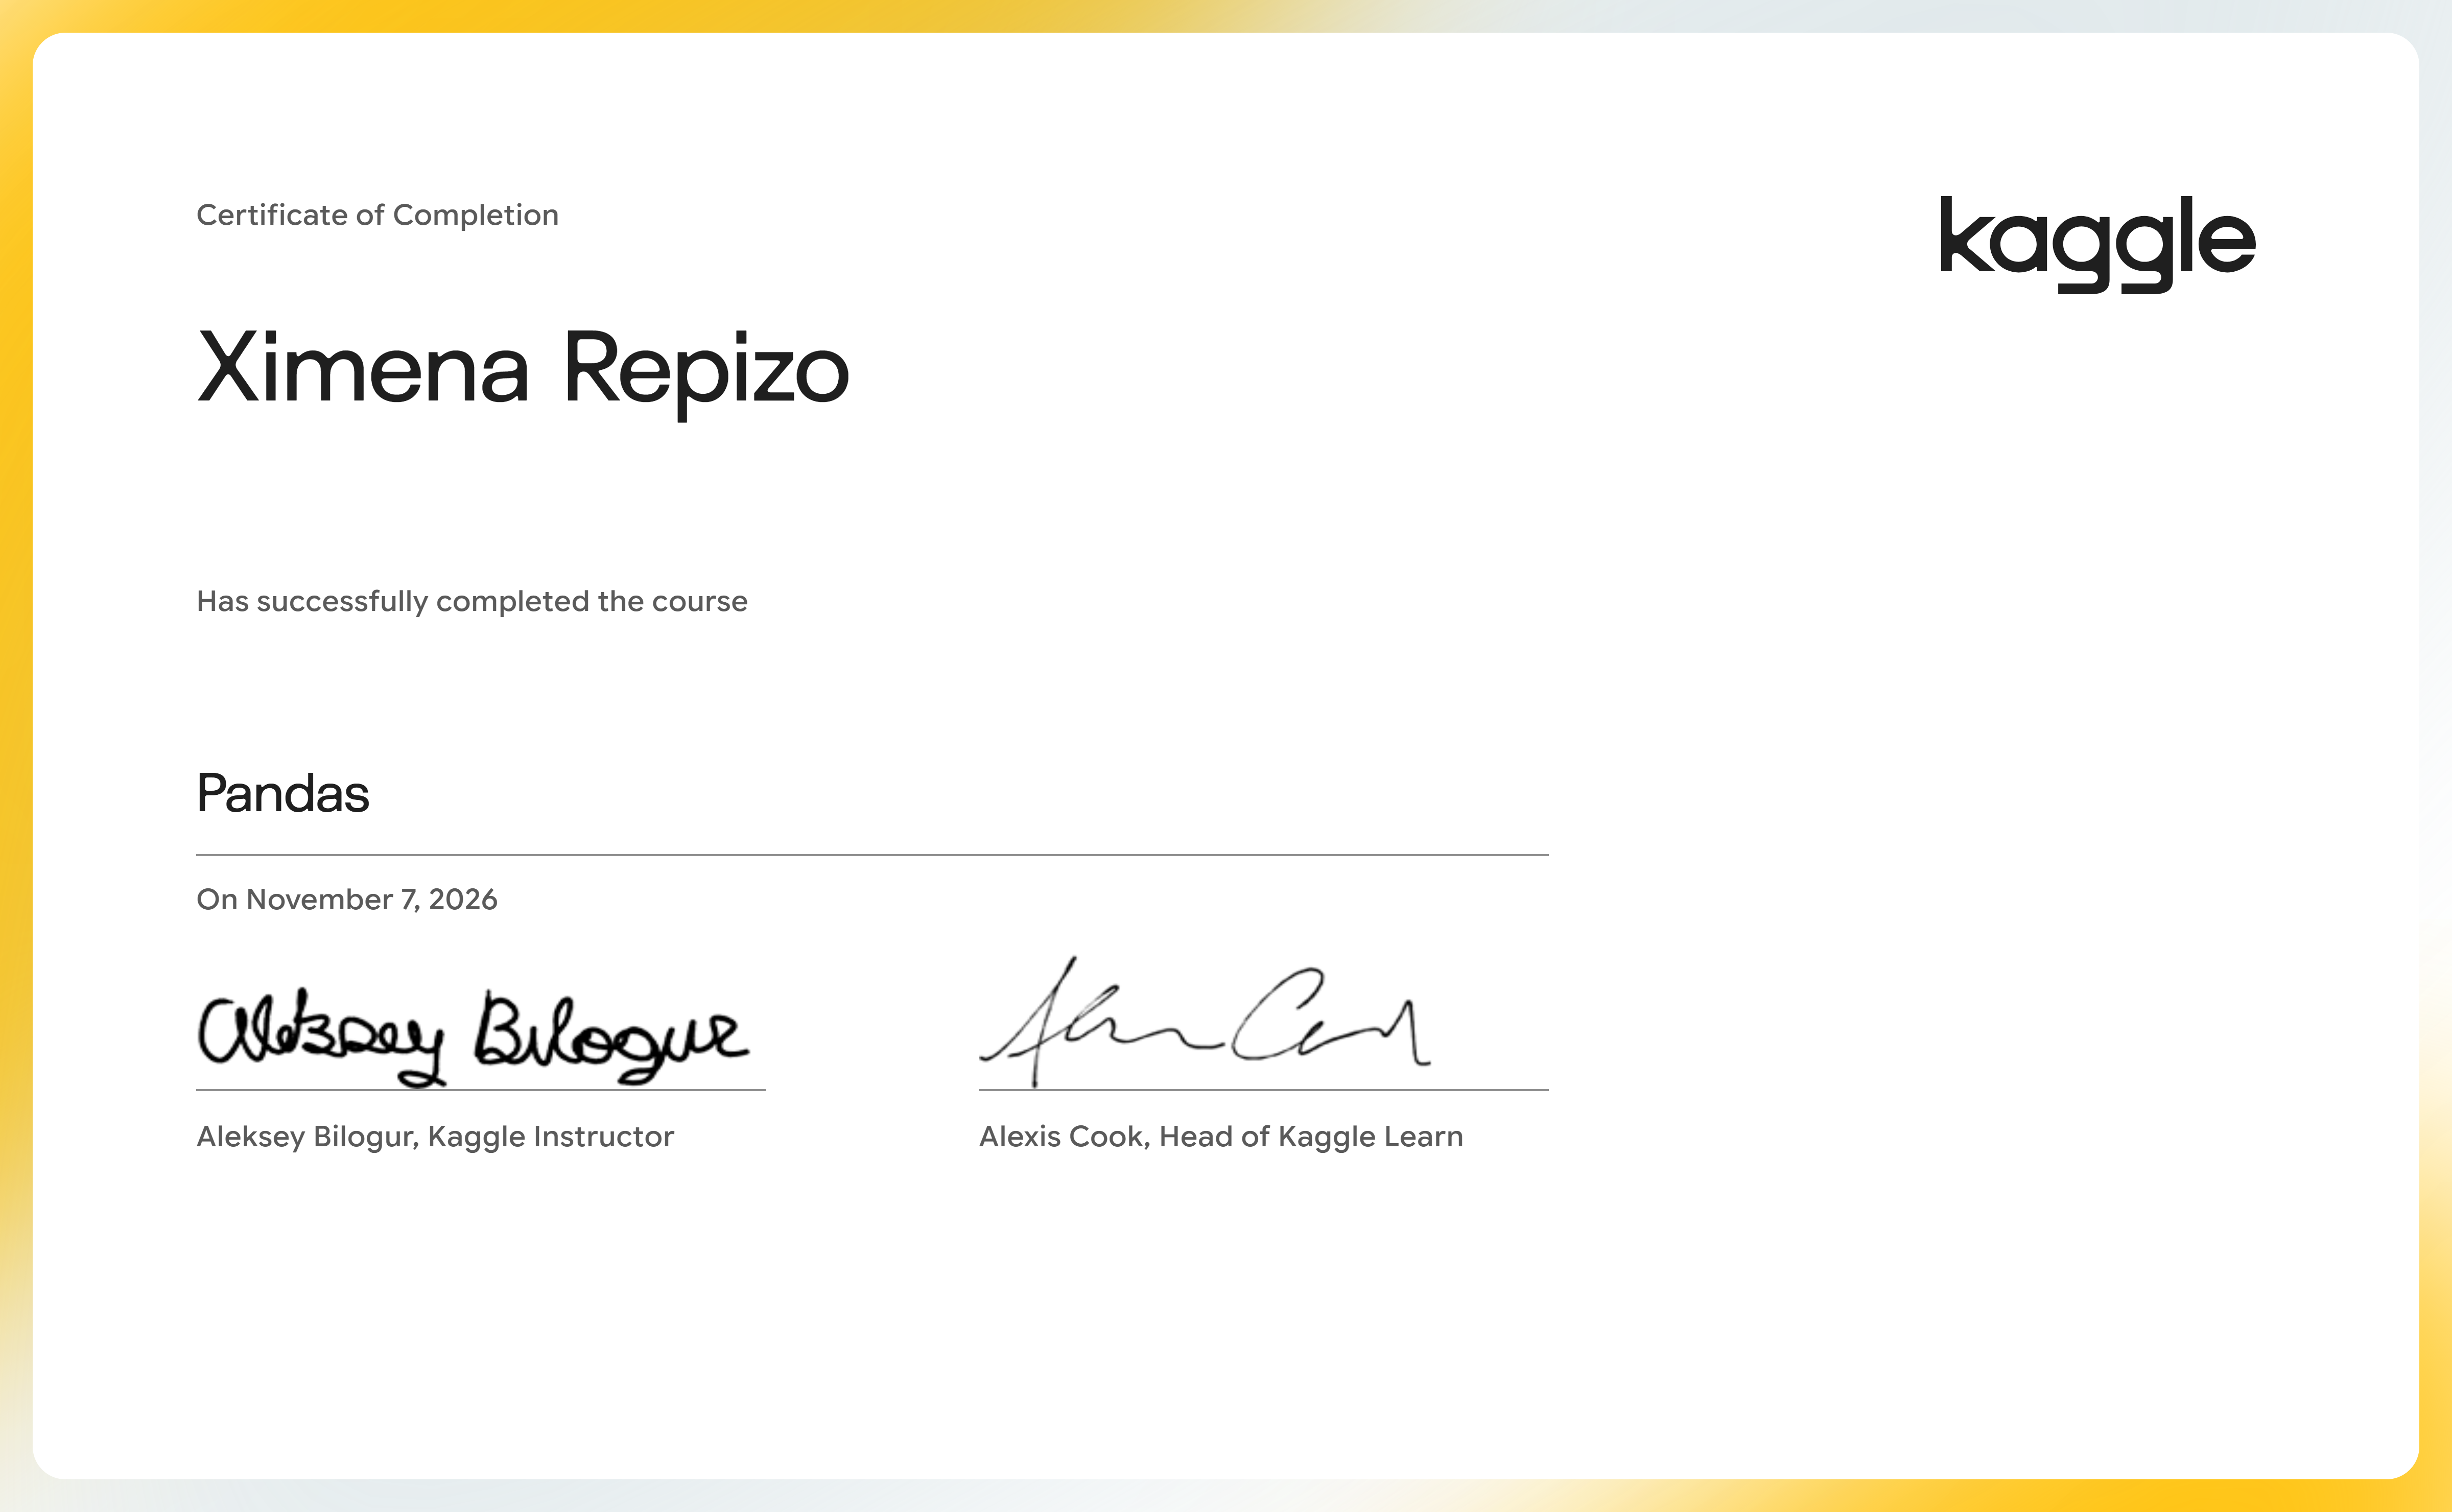

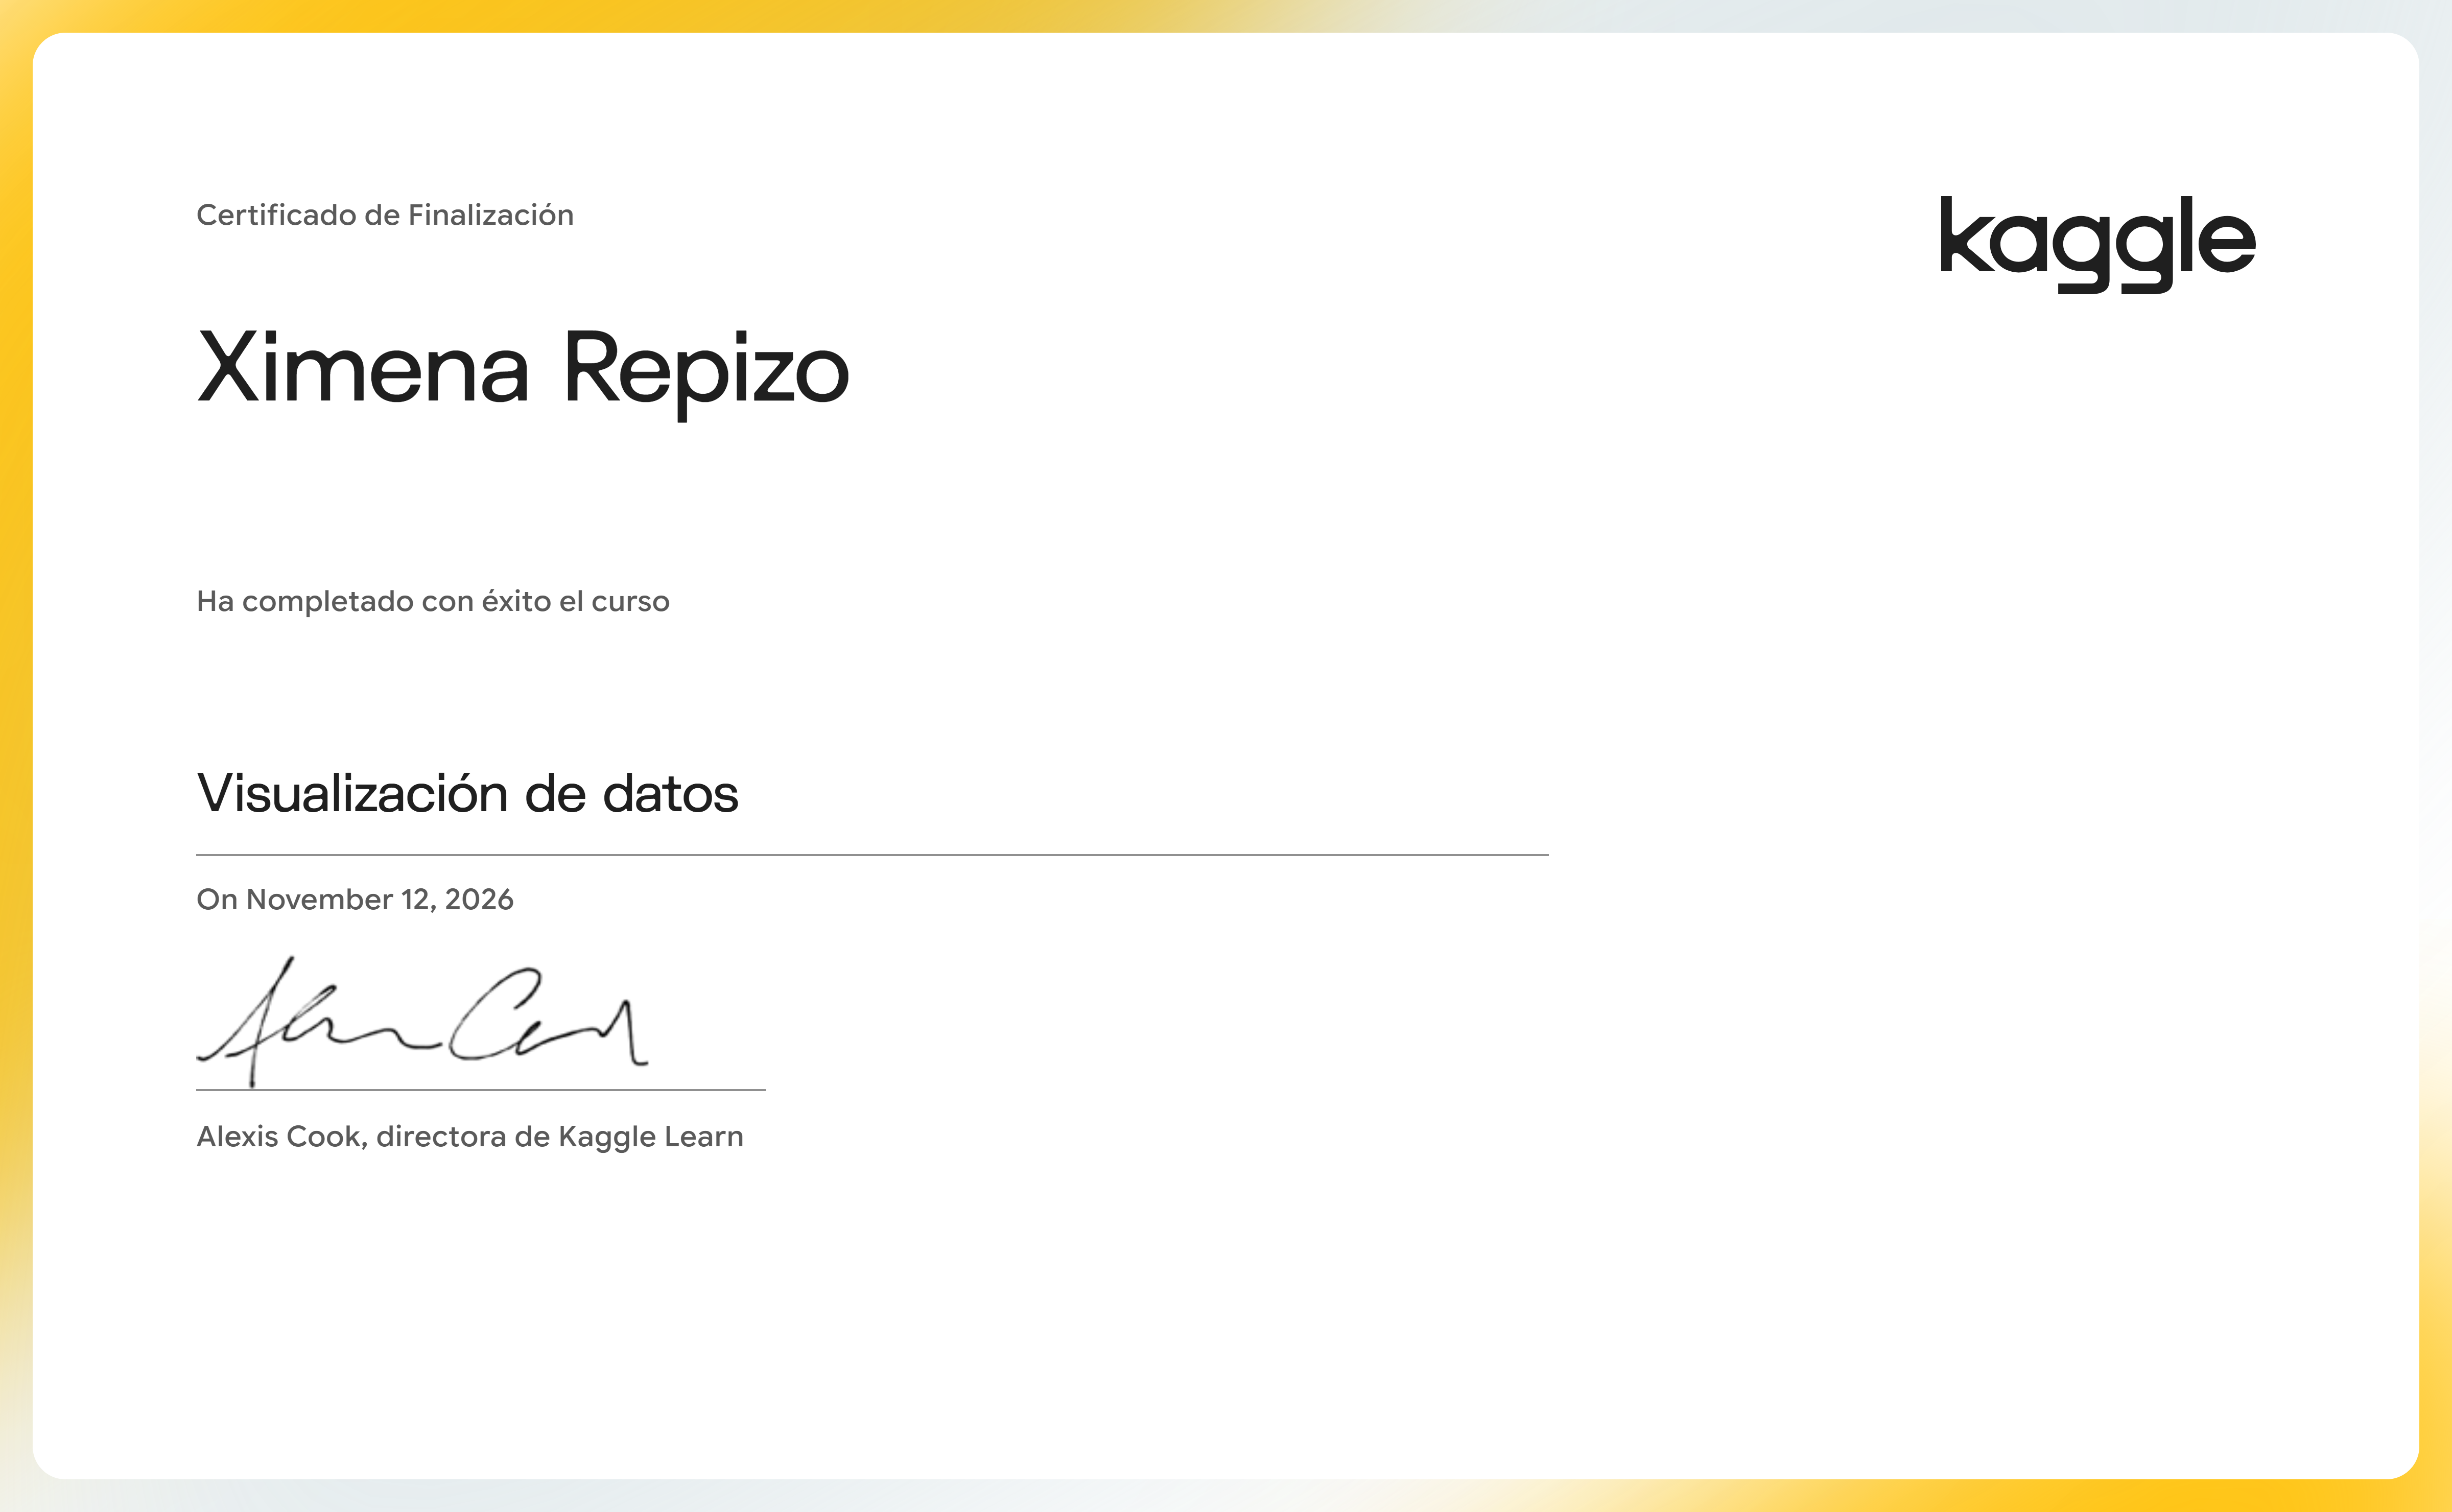


**Introducción**


Históricamente en diferentes lugares del mundo se han presentado sismos y terremotos de magnitudes altas las cuales han afectado ciudades y pueblos, por las destrucciones significativas del las estructuras que generan estas actividades sísmicas. Por lo cual, el dataset Terremotos relevantes, 1965 - 2016, información que recolecta el Centro Nacional de Información Sísmica(NEIC) permite tener conocimiento sobre la fecha, hora y lugar de todos los terremotos con magnitudes de 5,5 o más. Con esta información recolectada del dataset para el área de ciencia y analítica de datos permite desarrollar diferentes gráficos los cuales se analizaran información importante sobre la evolución en el tiempo de estas actividades sísmicas. 
_¿Dónde se concentran los terremotos más fuertes del mundo?_
Como pregunta central se busca tener conocimiento de los paises mas afectados o donde mas se presentan sistmos o terremotos durante los años 1965 - 2016. 
A traves de la metodologia Análisis Exploratorio de Dato (EDA)
- Los aspectos, características o cantidades observadas en estas unidades se denominan variables, ya que cambian de una unidad a otra.
- Un dato es el producto de observar una variable, también conocido como observación.
- Un conjunto de datos es una colección de observaciones de una o más variables medidas sobre varias unidades de la población.

**Objetivos**

*   **Objetivo General:** Desarrollar un Análisis Exploratorio de Datos (EDA) completo sobre el dataset seleccionado, aplicando métricas estadísticas, técnicas de preprocesamiento, visualización científica y análisis crítico asistido por IA.

*   **Objetivos Específicos:**

  1.   Realizar la carga, limpieza e inspección de estructura
del dataset.

  2.   Calcular métricas descriptivas, matrices de correlación y pruebas de hipótesis formales.

  3.   Preprocesar variables mediante categorización, escalamiento y codificación.

  4.  Construir y analizar 8 gráficos científicos alineados con buenas prácticas de visualización.

  5.  Evaluar críticamente los hallazgos y el desempeño de modelos de IA en cada fase.

## Parte 0: Carga y exploración inicial del dataset

In [4]:
# ==========================================
# PARTE 0: IMPORTACIÓN Y EXPLORACIÓN INICIAL
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder

# Configuración visual global
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

ModuleNotFoundError: No module named 'pandas'

In [ ]:

# 1. Carga del Dataset (reemplazar la ruta o URL)
url_o_ruta = "C:/Users/alexa/OneDrive - Universidad Nacional Abierta y a Distancia/Desktop/Ximena/UNAD/ULTIMO SEMESTRE/PROGRAMACIÓN PARA EL ANALISIS DE DATOS/FASE 3/archive/database.csv"
df = pd.read_csv(url_o_ruta)

# 2. Visualización de primeros y últimos registros
print("=== PRIMEROS 5 REGISTROS ===")
display(df.head())

print("\n=== ÚLTIMOS 5 REGISTROS ===")
display(df.tail())

# 3. Estructura y dimensión del DataFrame
print("\n=== ESTRUCTURA DEL DATAFRAME ===")
df.info()

print(f"\nNúmero total de filas (registros): {df.shape[0]}")
print(f"Número total de columnas (variables): {df.shape[1]}")

# 4. Tipos de variables y conteo de valores nulos
print("\n=== CONTEO DE VALORES FALTANTES POR COLUMNA ===")
null_summary = pd.DataFrame({
    'Tipo_Dato': df.dtypes,
    'Valores_Nulos': df.isnull().sum(),
    'Porcentaje_Nulos (%)': (df.isnull().sum() / len(df)) * 100
})
display(null_summary)

=== PRIMEROS 5 REGISTROS ===


,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status
0,01/02/1965,13:44:18,19.246,145.616,Earthquake,131.6,NaN,NaN,6.0,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860706,ISCGEM,ISCGEM,ISCGEM,Automatic
1,01/04/1965,11:29:49,1.863,127.352,Earthquake,80.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860737,ISCGEM,ISCGEM,ISCGEM,Automatic
2,01/05/1965,18:05:58,-20.579,-173.972,Earthquake,20.0,NaN,NaN,6.2,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860762,ISCGEM,ISCGEM,ISCGEM,Automatic
3,01/08/1965,18:49:43,-59.076,-23.557,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860856,ISCGEM,ISCGEM,ISCGEM,Automatic
4,01/09/1965,13:32:50,11.938,126.427,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860890,ISCGEM,ISCGEM,ISCGEM,Automatic



=== ÚLTIMOS 5 REGISTROS ===


,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status
23407,12/28/2016,08:22:12,38.3917,-118.8941,Earthquake,12.30,1.2,40.0,5.6,ML,...,18.0,42.47,0.120,NaN,0.1898,NN00570710,NN,NN,NN,Reviewed
23408,12/28/2016,09:13:47,38.3777,-118.8957,Earthquake,8.80,2.0,33.0,5.5,ML,...,18.0,48.58,0.129,NaN,0.2187,NN00570744,NN,NN,NN,Reviewed
23409,12/28/2016,12:38:51,36.9179,140.4262,Earthquake,10.00,1.8,NaN,5.9,MWW,...,NaN,91.00,0.992,4.8,1.5200,US10007NAF,US,US,US,Reviewed
23410,12/29/2016,22:30:19,-9.0283,118.6639,Earthquake,79.00,1.8,NaN,6.3,MWW,...,NaN,26.00,3.553,6.0,1.4300,US10007NL0,US,US,US,Reviewed
23411,12/30/2016,20:08:28,37.3973,141.4103,Earthquake,11.94,2.2,NaN,5.5,MB,...,428.0,97.00,0.681,4.5,0.9100,US10007NTD,US,US,US,Reviewed



=== ESTRUCTURA DEL DATAFRAME ===
<class 'pandas.DataFrame'>
RangeIndex: 23412 entries, 0 to 23411
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Date                        23412 non-null  str    
 1   Time                        23412 non-null  str    
 2   Latitude                    23412 non-null  float64
 3   Longitude                   23412 non-null  float64
 4   Type                        23412 non-null  str    
 5   Depth                       23412 non-null  float64
 6   Depth Error                 4461 non-null   float64
 7   Depth Seismic Stations      7097 non-null   float64
 8   Magnitude                   23412 non-null  float64
 9   Magnitude Type              23409 non-null  str    
 10  Magnitude Error             327 non-null    float64
 11  Magnitude Seismic Stations  2564 non-null   float64
 12  Azimuthal Gap               7299 non-null   float64
 13  Horizont

,Tipo_Dato,Valores_Nulos,Porcentaje_Nulos (%)
Date,str,0,0.000000
Time,str,0,0.000000
Latitude,float64,0,0.000000
Longitude,float64,0,0.000000
Type,str,0,0.000000
Depth,float64,0,0.000000
Depth Error,float64,18951,80.945669
Depth Seismic Stations,float64,16315,69.686486
Magnitude,float64,0,0.000000
Magnitude Type,str,3,0.012814



# **PARTE 1: Parámetros y Métricas Descriptivas**

=== MÉTRICAS NUMÉRICAS CON COEFICIENTE DE VARIACIÓN ===


,count,mean,std,min,25%,50%,75%,max,CV (%)
Latitude,23412.0,1.679033,30.113183,-77.080000,-18.65300,-3.5685,26.19075,86.005,1793.483556
Longitude,23412.0,39.639961,125.511959,-179.997000,-76.34975,103.9820,145.02625,179.998,316.629876
Depth,23412.0,70.767911,122.651898,-1.100000,14.52250,33.0000,54.00000,700.000,173.315696
Depth Error,4461.0,4.993115,4.875184,0.000000,1.80000,3.5000,6.30000,91.295,97.638131
Depth Seismic Stations,7097.0,275.364098,162.141631,0.000000,146.00000,255.0000,384.00000,934.000,58.882633
Magnitude,23412.0,5.882531,0.423066,5.500000,5.60000,5.7000,6.00000,9.100,7.191898
Magnitude Error,327.0,0.071820,0.051466,0.000000,0.04600,0.0590,0.07550,0.410,71.660054
Magnitude Seismic Stations,2564.0,48.944618,62.943106,0.000000,10.00000,28.0000,66.00000,821.000,128.600670
Azimuthal Gap,7299.0,44.163532,32.141486,0.000000,24.10000,36.0000,54.00000,360.000,72.778341
Horizontal Distance,1604.0,3.992660,5.377262,0.004505,0.96875,2.3195,4.72450,37.874,134.678697



=== MÉTRICAS DESCRIPTIVAS CATEGÓRICAS ===


C:\Users\alexa\AppData\Local\Temp\ipykernel_3964\1499308499.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns


,count,unique,top,freq
Date,23412,12401,03/11/2011,128
Time,23412,20472,02:56:58,5
Type,23412,4,Earthquake,23232
Magnitude Type,23409,10,MW,7722
ID,23412,23412,ISCGEM860706,1
Source,23412,13,US,20630
Location Source,23412,48,US,20350
Magnitude Source,23412,24,US,10458
Status,23412,2,Reviewed,20773


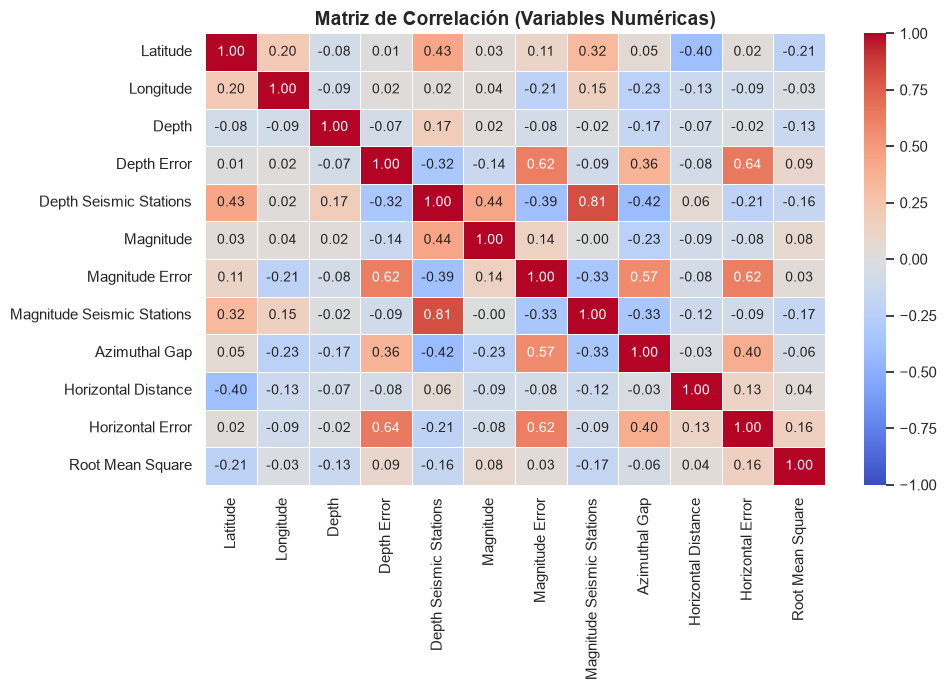


=== ESTADÍSTICAS DE 'Latitude' AGRUPADAS POR 'Date' ===


,count,mean,std,min,25%,50%,75%,max
Date,,,,,,,,
01/01/1967,2.0,-13.21850,2.854590,-15.2370,-14.227750,-13.21850,-12.209250,-11.2000
01/01/1969,1.0,51.09600,NaN,51.0960,51.096000,51.09600,51.096000,51.0960
01/01/1970,1.0,-29.40000,NaN,-29.4000,-29.400000,-29.40000,-29.400000,-29.4000
01/01/1971,1.0,-4.19000,NaN,-4.1900,-4.190000,-4.19000,-4.190000,-4.1900
01/01/1972,1.0,-17.02100,NaN,-17.0210,-17.021000,-17.02100,-17.021000,-17.0210
...,...,...,...,...,...,...,...,...
12/31/2014,2.0,4.65525,12.859515,-4.4378,0.108725,4.65525,9.201775,13.7483
12/31/2015,1.0,11.15350,NaN,11.1535,11.153500,11.15350,11.153500,11.1535
1975-02-23T02:58:41.000Z,1.0,8.01700,NaN,8.0170,8.017000,8.01700,8.017000,8.0170



=== DETECCIÓN DE OUTLIERS EN 'Latitude' ===
Q1 (25%): -18.65 | Q3 (75%): 26.19 | IQR: 44.84
Límite Inferior: -85.92 | Límite Superior: 93.46
Cantidad de Outliers detectados: 0 (0.00% del total)

=== PRUEBAS DE HIPÓTESIS ===
Welch t-test: Magnitude según Status (Automatic n=2639 vs Reviewed n=20773)
t = 15.2750, p-value = 6.2068e-51
Chi-cuadrada de independencia: Date (año) vs Type
chi2 = 474.9817, grados de libertad = 153, p-value = 1.1246e-34
Celdas con frecuencia esperada < 5: 155 de 208
Nota: un p-value pequeño indica asociación estadística, no causalidad; revisar frecuencias esperadas y el desbalance de Type antes de interpretar.


In [ ]:
# ==========================================
# PARTE 1: ESTADÍSTICA DESCRIPTIVA Y PRUEBAS
# ==========================================

# 1.1 Variables Numéricas y Coeficiente de Variación (CV)
num_cols = df.select_dtypes(include=[np.number]).columns
num_desc = df[num_cols].describe().T

# Cálculo del Coeficiente de Variación: CV = (std / mean) * 100
num_desc['CV (%)'] = (num_desc['std'] / num_desc['mean']) * 100
print("=== MÉTRICAS NUMÉRICAS CON COEFICIENTE DE VARIACIÓN ===")
display(num_desc[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'CV (%)']])

# 1.2 Variables Categóricas
cat_cols = df.select_dtypes(include=['object', 'category']).columns
if len(cat_cols) > 0:
    print("\n=== MÉTRICAS DESCRIPTIVAS CATEGÓRICAS ===")
    display(df[cat_cols].describe().T)

# 1.3 Matriz de Correlación
plt.figure(figsize=(10, 7))
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matriz de Correlación (Variables Numéricas)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 1.4 Estadísticas por Grupo (groupby) y Detección de Outliers (IQR)
# Ajuste 'col_cat' y 'col_num' a las columnas de su dataset
col_cat = cat_cols[0] if len(cat_cols) > 0 else 'categoria_ejemplo'
col_num = num_cols[0]

print(f"\n=== ESTADÍSTICAS DE '{col_num}' AGRUPADAS POR '{col_cat}' ===")
if col_cat in df.columns:
    display(df.groupby(col_cat)[col_num].describe())

# Detección de Outliers por Rango Intercuartílico (IQR)
Q1 = df[col_num].quantile(0.25)
Q3 = df[col_num].quantile(0.75)
IQR = Q3 - Q1
lim_inferior = Q1 - 1.5 * IQR
lim_superior = Q3 + 1.5 * IQR

outliers = df[(df[col_num] < lim_inferior) | (df[col_num] > lim_superior)]
print(f"\n=== DETECCIÓN DE OUTLIERS EN '{col_num}' ===")
print(f"Q1 (25%): {Q1:.2f} | Q3 (75%): {Q3:.2f} | IQR: {IQR:.2f}")
print(f"Límite Inferior: {lim_inferior:.2f} | Límite Superior: {lim_superior:.2f}")
print(f"Cantidad de Outliers detectados: {len(outliers)} ({len(outliers)/len(df)*100:.2f}% del total)")

# 1.5 Pruebas de hipótesis: t de Welch y Chi-cuadrada (Date vs Type)
print("\n=== PRUEBAS DE HIPÓTESIS ===")

# A. Welch: comparar Magnitude entre las dos categorías de Status
# No requiere asumir igualdad de varianzas (equal_var=False).
status_vals = df['Status'].dropna().unique()
if len(status_vals) == 2:
    grupo1 = df.loc[df['Status'] == status_vals[0], 'Magnitude'].dropna()
    grupo2 = df.loc[df['Status'] == status_vals[1], 'Magnitude'].dropna()
    t_stat, p_val = stats.ttest_ind(grupo1, grupo2, equal_var=False)
    print(f"Welch t-test: Magnitude según Status ({status_vals[0]} n={len(grupo1)} vs {status_vals[1]} n={len(grupo2)})")
    print(f"t = {t_stat:.4f}, p-value = {p_val:.4e}")
else:
    print("Welch t-test omitido: Status no contiene exactamente dos categorías válidas.")

# B. Chi-cuadrada: Date (año derivado de la fecha) frente a Type
# Se agrupa Date por año para evitar una categoría por fecha individual.
fecha_parseada = pd.to_datetime(df['Date'], format='mixed', errors='coerce', utc=True)
fecha_anio = fecha_parseada.dt.year.rename('Date')
tabla_contingencia = pd.crosstab(fecha_anio, df['Type'])
chi2, p_chi, dof, esperadas = stats.chi2_contingency(tabla_contingencia)
print("Chi-cuadrada de independencia: Date (año) vs Type")
print(f"chi2 = {chi2:.4f}, grados de libertad = {dof}, p-value = {p_chi:.4e}")
print(f"Celdas con frecuencia esperada < 5: {(esperadas < 5).sum()} de {esperadas.size}")
print("Nota: un p-value pequeño indica asociación estadística, no causalidad; revisar frecuencias esperadas y el desbalance de Type antes de interpretar.")


#**Ejercicio IA Parte 1: Error de Causalidad en Correlación**

**Instrucción:** Ejecute el siguiente prompt en su herramienta de IA (ChatGPT, Gemini, etc.) reemplazando los corchetes con los datos de su matriz de correlación:

"*Tengo una matriz de correlación de un dataset de Terremotos relevantes, 1965–2016 (NEIC). Las variables con mayor correlación son `Depth Seismic Stations` y `Magnitude Seismic Stations` con una correlación de $r = 0,81$. Esto significa que `Depth Seismic Stations` CAUSA `Magnitude Seismic Stations`. ¿Cómo puedo usar esta relación causal para hacer predicciones?*"

#**Documentación en Markdown:**

1.  **Respuesta dada por la IA (Fragmento clave):**

              "Cuidado: una correlación alta no significa que una variable cause la otra. Ese es el error más común al interpretar una matriz de correlación, y conviene corregirlo antes de seguir.Qué dice realmente ese valor
              Una correlación de, digamos, 0.85 entre A y B solo dice que se mueven juntas: cuando A sube, B tiende a subir. No dice por qué. Puede pasar por cuatro razones distintas:
              A causa B (lo que asumiste).
              B causa A (la flecha va al revés).
              Una tercera variable C causa a las dos. El ejemplo clásico: las ventas de helado y los ahogamientos en piscina correlacionan fuerte, pero ninguna causa la otra; ambas las causa el calor del verano.
              Pura coincidencia o tendencia compartida. Dos cosas que crecen con los años correlacionan sin ninguna relación real.
              La frase "correlación no implica causalidad" es la regla número uno de la estadística, y aplica exactamente aquí.
              Cómo saber si hay causalidad de verdad
              No basta con mirar la tabla. Necesitas:
              Un mecanismo plausible. ¿Tiene sentido físico o lógico que A afecte a B? Si no puedes explicar el "cómo", sospecha.
              Que A ocurra antes que B. Si B pasa primero, no puede ser su causa.
              Un experimento controlado, si es posible: cambia A a propósito y observa si B cambia. En datos observacionales (como un dataset histórico) casi nunca puedes hacer esto, y por eso la causalidad queda como hipótesis, no como hecho.
              Controlar otras variables. Si al quitar el efecto de C la correlación entre A y B desaparece, entonces C era la verdadera causa.
              Y ahora la parte práctica: predecir no requiere causalidad
              Aquí está la buena noticia. Para predecir no necesitas demostrar que A causa B. Solo necesitas que la relación sea estable y se mantenga en el futuro. Un modelo puede predecir perfectamente usando variables correlacionadas, aunque no haya causalidad.
              Eso sí, tiene consecuencias importantes:
              Si la relación es causal, es más robusta. Si cambias A, B cambiará de verdad. Puedes intervenir.
              Si solo es correlación, la predicción puede romperse. Si desaparece la causa común (por ejemplo, cambia la estación del año), la relación se cae y el modelo falla.
              Para predecir necesitas datos futuros de A. Si A es "el precio del petróleo" y B es "el costo del transporte", puedes predecir B solo si antes predices A. Ahí la cadena se complica.Cómo plantearlo bien en tu caso
              En lugar de "A causa B", formula la pregunta así: "¿Qué tan bien puedo predecir B usando A, y se mantiene esa relación fuera de los datos con los que la aprendí?"
              El procedimiento sería:
              Divide los datos: entrena el modelo con una parte y pruébalo con otra que nunca vio.
              Mide el error en la parte de prueba, no en la de entrenamiento. Si el error se dispara, la relación no era tan estable.
              Prueba sin A para ver cuánto aporta realmente. Si el modelo predice igual de bien sin ella, la correlación era decorativa.Revisa el mecanismo antes de afirmar cualquier cosa causal en tus conclusiones.
              En una frase: usa la correlación para predecir, pero no la uses para afirmar causas. Y si tu trabajo pide explicar el "por qué", di "están asociadas" en lugar de "una causa la otra" hasta que tengas evidencia real de causalidad."

2. **Cuestionamiento de la Premisa:** La IA no aceptó la premisa causal; la corrigió. Una correlación de 0,81 es una asociación lineal positiva fuerte, pero no demuestra que el número de estaciones que registran la profundidad cause el número de estaciones que registran la magnitud.

3. **Explicación Conceptual:** El coeficiente de Pearson cuantifica la dirección y fuerza de una asociación lineal entre dos variables. No identifica el mecanismo que produce la asociación, ni establece temporalidad o dirección causal. Puede existir causalidad inversa, una variable confusora o un factor común que influya en ambas variables. Para afirmar causalidad se requeriría un diseño que permita controlar explicaciones alternativas y establecer un mecanismo; la matriz de correlación, por sí sola, no lo permite.

4. **Ejemplo Real con el Dataset:** En el dataset NEIC 1965–2016, `Depth Seismic Stations` y `Magnitude Seismic Stations` presentan $r = 0,81$. Una explicación plausible es que ambos conteos reflejen cobertura, disponibilidad de estaciones, calidad del registro y protocolos de procesamiento de la red. No se puede afirmar que registrar más estaciones de profundidad provoque que se registren más estaciones de magnitud: pueden responder a condiciones comunes de observación del evento.

5. **Interpretación CORRECTA:** Existe una asociación lineal positiva fuerte ($r = 0,81$) entre `Depth Seismic Stations` y `Magnitude Seismic Stations`. Los eventos con más estaciones reportadas para una medición tienden también a tener más estaciones reportadas para la otra. Esta asociación es compatible con diferencias en cobertura y calidad de observación, pero no demuestra causalidad ni permite inferir un efecto de una variable sobre la otra sin un análisis adicional.

# **Bitácora de IA - Parte 1**

*   **¿Usaste IA en esta parte?:** Si

*   **Prompt exacto utilizado:** [Tengo una matriz de correlación de un dataset de Terremotos relevantes, 1965–2016 (NEIC). Las variables con mayor correlación son `Depth Seismic Stations` y `Magnitude Seismic Stations` con una correlación de $r = 0,81$. Esto significa que `Depth Seismic Stations` CAUSA `Magnitude Seismic Stations`. ¿Cómo puedo usar esta relación causal para hacer predicciones?]
*   **Resumen del output recibido:** [La IA Ecogpt, en la respuesta indeica que se puede usr la correlacion para predecir, pero no para afirmar causas. Tambien indica, una correlación de, digamos, 0.85 entre A y B solo dice que se mueve juntas: cuando A sube, B tiende a subir. No dece que por qué. Puede pasar por cuatro razones distintas: A causa B, B causa A, una tercera variable C causa a los dos y pura coincidencia o tendencia compartida.]
*   **¿Qué modificaste y por qué?:** [No, el ejercicio de la IA solicita pasar el texto sin modificaciones.]
*   **¿Qué aprendiste o qué error detectaste?:** La información fue clara, una correlacion anta entre A y B solo indica que ambas variables se mueven juntas, no que una cause a la otra, ya que esa realción podría deberse a causalidad inversa (B causa A), a una tercera variable C que provoca a las dos o a una simple concidencia o tendencia compartida, para hablar de cuasalidad real habría falta un mecanismo, que A ocurra antes que B, un experimento controlado y el control de otras variables.

# **PARTE 2: Escalamiento, Estandarización y Codificación**


In [ ]:
# ==========================================
# PARTE 2: TRANSFORMACIÓN Y CODIFICACIÓN
# ==========================================

# 2.1 Categorización de una Variable Continua en Bins/Rangos
col_continua = num_cols[8]
df['rango_' + col_continua] = pd.qcut(df[col_continua], q=4, labels=['Bajo', 'Medio-Bajo', 'Medio-Alto', 'Alto'])
print("=== CATEGORIZACIÓN DE VARIABLE CONTINUA POR PERCENTILES ===")
print(df['rango_' + col_continua].value_counts())

# 2.2 Escalamiento de Variables Numéricas
# Selección de 2 variables continuas con diferentes escalas
var1 = num_cols[8]
var2 = num_cols[1] if len(num_cols) > 1 else num_cols[8]

# Mostramos estadísticas ANTES de escalar
print("\n=== ESTADÍSTICAS ANTES DEL ESCALAMIENTO ===")
display(df[[var1, var2]].describe().T[['mean', 'std', 'min', 'max']])

# Aplicación de MinMaxScaler y StandardScaler
min_max_scaler = MinMaxScaler()
standard_scaler = StandardScaler()

df[var1 + '_minmax'] = min_max_scaler.fit_transform(df[[var1]])
df[var2 + '_standard'] = standard_scaler.fit_transform(df[[var2]])

print("\n=== ESTADÍSTICAS DESPUÉS DEL ESCALAMIENTO ===")
display(df[[var1 + '_minmax', var2 + '_standard']].describe().T[['mean', 'std', 'min', 'max']])

# 2.3 Codificación de Variable Categórica
if len(cat_cols) > 8:
    col_a_codificar = cat_cols[8]

    # Opción A: LabelEncoder
    le = LabelEncoder()
    df[col_a_codificar + '_label'] = le.fit_transform(df[col_a_codificar].astype(str))

    # Opción B: One-Hot Encoding (pd.get_dummies)
    df_encoded = pd.get_dummies(df, columns=[col_a_codificar], prefix='cat')

    print(f"\n=== CODIFICACIÓN DE '{col_a_codificar}' CON LABEL ENCODER ===")
    display(df[[col_a_codificar, col_a_codificar + '_label']].head())


=== CATEGORIZACIÓN DE VARIABLE CONTINUA POR PERCENTILES ===
rango_Azimuthal Gap
Medio-Bajo    1849
Bajo          1832
Alto          1810
Medio-Alto    1808
Name: count, dtype: int64

=== ESTADÍSTICAS ANTES DEL ESCALAMIENTO ===


,mean,std,min,max
Azimuthal Gap,44.163532,32.141486,0.000,360.000
Longitude,39.639961,125.511959,-179.997,179.998



=== ESTADÍSTICAS DESPUÉS DEL ESCALAMIENTO ===


,mean,std,min,max
Azimuthal Gap_minmax,1.226765e-01,0.089282,0.000000,1.000000
Longitude_standard,4.248931e-17,1.000021,-1.749966,1.118308



=== CODIFICACIÓN DE 'Status' CON LABEL ENCODER ===


,Status,Status_label
0,Automatic,0
1,Automatic,0
2,Automatic,0
3,Automatic,0
4,Automatic,0


# **Justificación en Markdown - Parte 2**

**Argumentación de Escalamiento:**

* **MinMaxScaler en _Azimuthal Gap_:** esta variable es un ángulo y por naturaleza tiene un rango fijo (de 0° a 360°). MinMaxScaler la lleva a una escala de 0 a 1 conservando la forma original de la distribución. Sin embargo, la variable tiene valores extremos: la mediana es 36, el 75 % de los datos llega hasta 54 y el máximo es 360. Por eso, después de escalar, la media queda en 0,12 y la mayoría de los datos se agrupan cerca de 0. Es decir, MinMaxScaler es sensible a los outliers, y esto es una limitación de esta elección.

* **StandardScaler en _Longitude_:** esta variable no sigue una distribución normal, porque su media (39,6) está lejos de la mediana (104,0), lo que indica asimetría. Aun así, se usó StandardScaler porque tiene una escala muy distinta a otras variables (desviación estándar de 125,5) y lo que se busca es dejarla con media 0 y desviación estándar 1 (resultado obtenido: media ≈ 0 y desviación 1,0). Esto permite compararla con otras variables en la misma escala. Su limitación es que el puntaje z se interpreta mejor cuando la distribución se parece a una normal.

**Análisis de Codificación:**

* **LabelEncoder en _Status_:** esta variable tiene solo 2 categorías (Automatic y Reviewed), y la mayoría de los registros (20.773) son Reviewed. Con dos categorías, LabelEncoder las convierte en 0 y 1 sin crear un orden falso entre ellas, por eso es una opción adecuada y simple.

* **One-Hot Encoding (_get_dummies_):** crea una columna por categoría (cat_Automatic y cat_Reviewed). Con solo 2 categorías una de las columnas es redundante, por lo que aquí no aporta información nueva. Sería más útil en variables con más categorías y sin orden, como _Magnitude Type_ (10 categorías) o _Source_ (13), porque evita que el modelo interprete un orden que no existe.

# **Ejercicio IA Parte 2: IA como Revisora del Código Propio**

**Paso 1:**  
[min_max_scaler = MinMaxScaler()
standard_scaler = StandardScaler()
df[var1 + '_minmax'] = min_max_scaler.fit_transform(df[[var1]])
df[var2 + '_standard'] = standard_scaler.fit_transform(df[[var2]])
print("\n=== ESTADÍSTICAS DESPUÉS DEL ESCALAMIENTO ===")
display(df[[var1 + '_minmax', var2 + '_standard']].describe().T[['mean', 'std', 'min', 'max']])
2.3 Codificación de Variable Categórica
if len(cat_cols) > 0:
    col_a_codificar = cat_cols[0]
    # Opción A: LabelEncoder
    le = LabelEncoder()
    df[col_a_codificar + '_label'] = le.fit_transform(df[col_a_codificar].astype(str))
    # Opción B: One-Hot Encoding (pd.get_dummies)
    df_encoded = pd.get_dummies(df, columns=[col_a_codificar], prefix='cat')
    print(f"\n=== CODIFICACIÓN DE '{col_a_codificar}' CON LABEL ENCODER ===")
    display(df[[col_a_codificar, col_a_codificar + '_label']].head())]

**Paso 2:** Envíe su código a la IA con el siguiente prompt:
"Revisa el siguiente código Python que aplica escalamiento con sklearn. Evalúa:

  1.  Si la elección de MinMaxScaler vs StandardScaler es apropiada dado que [describe la distribución de tus variables].
  2.  Si hay mejoras de eficiencia o legibilidad.
  3.  Si el código sigue buenas prácticas de ciencia de datos: [Pega tu código]"
  
# **Documentación en Markdown:**

1.  **Sugerencias recibidas de la IA:**

    *   **Sugerencia 1 (elección del escalador):** `MinMaxScaler` es apropiado para `Latitude`: es una variable acotada físicamente entre $-90°$ y $90°$ (rango observado $-77,08$ a $86,01$) y sin outliers por IQR. `StandardScaler` es menos apropiado para `Longitude`: su media ($39,64$) está muy lejos de la mediana ($103,98$), lo que indica una distribución asimétrica y no aproximadamente normal, supuesto bajo el cual el puntaje $z$ es más interpretable.

    *   **Sugerencia 2 (longitud circular):** `Longitude` es una variable circular ($-180°$ y $+180°$ son el mismo meridiano). Un escalador lineal separa artificialmente sismos vecinos en regiones como Fiji, Tonga o las Aleutianas. Recomendó transformarla a $\sin$ y $\cos$ (o a coordenadas cartesianas 3D) antes de usarla en modelos basados en distancia.

    *   **Sugerencia 3 (buenas prácticas de código):** seleccionar las columnas por nombre y no por posición (`num_cols[0]`, `num_cols[1]`), encapsular el proceso en `ColumnTransformer` / `Pipeline` y ajustar (`fit`) el escalador solo con los datos de entrenamiento para evitar fuga de datos.

    *   **Sugerencia 4 (variables alternativas):** usar variables con escalas realmente distintas y sesgadas, como `Depth` (media $70,77$, mediana $33,0$, máximo $700$, CV $= 173$ %), con `RobustScaler`, en lugar de coordenadas geográficas.

2.  **Matriz de Decisiones:**

    * **Sugerencia 1 (elección del escalador): Adapto**

    → Razón: El preprocesamiento efectivamente escala `Azimuthal Gap` con `MinMaxScaler` y `Longitude` con `StandardScaler`. El gráfico 6 también compara `Magnitude` original con `Magnitude_minmax`, creado con `MinMaxScaler`. Por tanto, mantengo estas transformaciones tal como están en el código y justifico sus limitaciones: MinMax es sensible a valores extremos en `Azimuthal Gap` y `Magnitude`; StandardScaler centra y estandariza `Longitude`, pero no corrige su asimetría ni la naturaleza circular de la coordenada. No se escala `Latitude` en este bloque ni en el gráfico 6.

    * **Sugerencia 2 (longitud circular): Acepto**

    → Razón: `Longitude` es circular; -180° y +180° representan el mismo meridiano. El EDA no utiliza estas coordenadas en un modelo de distancia, por lo que conservo el escalamiento actual y dejo como mejora de modelado la representación seno/coseno de longitud.

    * **Sugerencia 3 (buenas prácticas de código): Adapto**

    → Razón: Seleccionar columnas por nombre sería más robusto que por posición. No implemento `Pipeline` ni partición train/test porque no se entrena un modelo predictivo en esta tarea. En un modelado posterior, los escaladores se ajustarían solo con el conjunto de entrenamiento.

    * **Sugerencia 4 (variables alternativas): Rechazo**

    → Razón: No reemplazo las variables seleccionadas por `Depth`, pues el ejercicio y el gráfico comparativo ya se construyen con `Azimuthal Gap`, `Longitude` y `Magnitude`. Para un modelado futuro de datos con valores extremos en profundidad, podría considerarse `RobustScaler`, pero no es parte del escalamiento realizado aquí.

3.  **Reflexión sobre la Metodología:** Compare la diferencia entre pedirle a la IA que genere el código desde cero frente a usarla como revisora de un trabajo propio.

    **Respuesta:** Pedirle a la IA que genere el código desde cero delega también las decisiones de diseño (qué variables escalar y con qué escalador): el resultado puede funcionar y aun así ser inadecuado, y es más difícil detectarlo porque no hay un criterio propio con qué contrastarlo. Usarla como revisora parte de decisiones ya justificadas con evidencia (cuartiles, outliers y CV de la Parte 1); la IA las contrasta, señala puntos ciegos (como la circularidad de la longitud) y yo decido qué aceptar, adaptar o rechazar. Aun así, la revisión exige verificar sus afirmaciones contra los datos, porque puede sugerir cambios que no aplican a la consigna (como cambiar las variables elegidas).

# **Bitácora de IA - Parte 2**

*   **¿Usaste IA en esta parte?:** Sí

*   **Prompt exacto utilizado:** Revisa el siguiente código Python que aplica escalamiento con sklearn. Evalúa: 1. Si la elección de MinMaxScaler vs StandardScaler es apropiada dado que Latitude va de -77,08 a 86,01 (media 1,68; desv. estándar 30,11; 0 outliers por IQR) y Longitude va de -179,997 a 179,998 (media 39,64; mediana 103,98; desv. estándar 125,51). 2. Si hay mejoras de eficiencia o legibilidad. 3. Si el código sigue buenas prácticas de ciencia de datos: (se adjuntó sin modificaciones el bloque 2.2 "Escalamiento de Variables Numéricas" del código de la Parte 2)

*   **Resumen del output recibido:** La IA (Claude) consideró adecuado MinMaxScaler para Latitude y cuestionó StandardScaler para Longitude porque no es normal y es una variable circular. Sugirió seleccionar columnas por nombre, usar ColumnTransformer/Pipeline y hacer el fit solo con datos de entrenamiento, y propuso RobustScaler con Depth.

*   **¿Qué modificaste y por qué?:** No modifiqué el código de escalamiento, porque la consigna exige comparar ambos escaladores con variables de distinta escala. Adapté la documentación para declarar la limitación de StandardScaler en Longitude y dejé la transformación seno/coseno y la selección por nombre como mejoras para la fase de modelado. Rechacé cambiar las variables por Depth.

*   **¿Qué aprendiste o qué error detectaste?:** La elección del escalador debe justificarse con la distribución de cada variable (en Longitude la media y la mediana difieren mucho) y las coordenadas geográficas requieren un tratamiento especial por ser circulares. También que no todas las sugerencias de la IA aplican a la consigna y que cada una debe contrastarse con los resultados antes de aceptarla.
    
3.  **Reflexión sobre la Metodología:**

Pedirle a la IA que genere el código desde cero implica delegarle también las decisiones de diseño, como qué variables escalar y con qué escalador. El código puede funcionar y aun así ser inadecuado, y es más difícil darse cuenta porque no hay un criterio propio con el cual compararlo.

En cambio, usarla como revisora de un trabajo propio parte de decisiones que ya estaban justificadas con evidencia de la Parte 1 (cuartiles, outliers y coeficiente de variación). En este caso, la IA contrastó esas decisiones y señaló puntos que yo no había considerado, como que la longitud es una variable circular. Además, yo conservé el control: acepté la sugerencia sobre la longitud circular, adapté las de la elección del escalador y la selección de columnas por nombre, y rechacé la de cambiar las variables por Depth.

Aun así, usarla como revisora exige verificar sus afirmaciones con los datos, porque puede proponer cambios que no aplican a la consigna. Por ejemplo, sugirió cambiar las variables elegidas, lo que habría obligado a rehacer el histograma comparativo de la Parte 3.


# **PARTE 3: Gráficos y Visualización Científica**

In [ ]:
# ==========================================
# PARTE 3: GENERACIÓN DE 8 GRÁFICOS
# ==========================================
sns.set_theme(style="whitegrid")

# ----------------------------------------------------------
# 0. PREPARACIÓN (año, zona geográfica y rangos)
# ----------------------------------------------------------
# La columna Date mezcla dos formatos (MM/DD/YYYY e ISO), por eso format='mixed'
df['Año'] = pd.to_datetime(df['Date'], format='mixed', errors='coerce', utc=True).dt.year

# Zona geográfica: cuadrícula de 10° x 10° (el dataset no trae país)
df['Zona'] = ("Lat " + (np.floor(df['Latitude'] / 10) * 10).astype(int).astype(str)
              + " / Lon " + (np.floor(df['Longitude'] / 10) * 10).astype(int).astype(str))

# Sismos "fuertes" = magnitud >= 7.0
fuertes = df[df['Magnitude'] >= 7.0].copy()

# Variable continua categorizada (Parte 2)
if 'rango_Azimuthal Gap' not in df.columns:
    df['rango_Azimuthal Gap'] = pd.qcut(df['Azimuthal Gap'], q=4,
                                        labels=['Bajo', 'Medio-Bajo', 'Medio-Alto', 'Alto'])


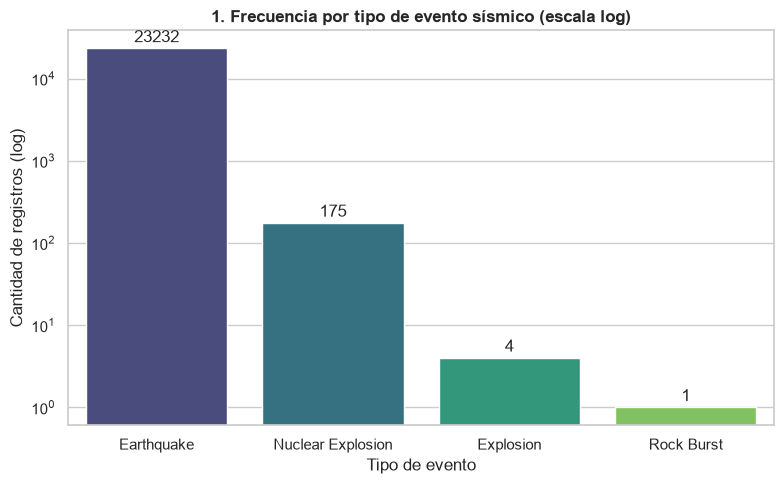

In [ ]:
# --- GRÁFICO 1: Diagrama de barras (variable categórica: Type) --- 
# ----------------------------------------------------------
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='Type', hue='Type', palette='viridis', legend=False,
                   order=df['Type'].value_counts().index)
ax.set_yscale('log')
for c in ax.containers:
    ax.bar_label(c, padding=2)
plt.title("1. Frecuencia por tipo de evento sísmico (escala log)", fontweight='bold')
plt.xlabel("Tipo de evento")
plt.ylabel("Cantidad de registros (log)")
plt.tight_layout()
plt.show()

### Comentario del Gráfico 1
- **Qué muestra:** Conteo de registros por tipo de evento, representado en escala logarítmica.
- **Qué patrón se observa:** `Earthquake` domina ampliamente los registros; las categorías restantes son mucho menos frecuentes, por lo que la escala log permite verlas.
- **Qué limitación presenta:** El fuerte desbalance dificulta comparar categorías pequeñas y el conteo refleja el catálogo disponible, no necesariamente la incidencia real de todos los eventos sísmicos.

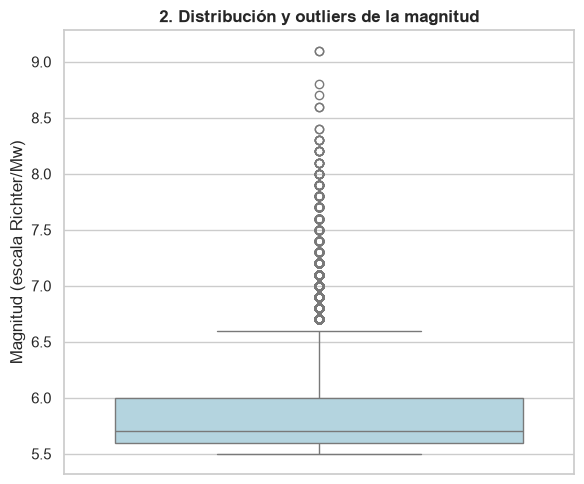

Outliers de magnitud (> 6.60): 1475 sismos


In [ ]:
# --- GRÁFICO 2: Boxplot ---

plt.figure(figsize=(6, 5))
sns.boxplot(data=df, y='Magnitude', color='lightblue')
plt.title("2. Distribución y outliers de la magnitud", fontweight='bold')
plt.ylabel("Magnitud (escala Richter/Mw)")
plt.tight_layout()
plt.show()

Q1, Q3 = df['Magnitude'].quantile([0.25, 0.75])
lim_sup = Q3 + 1.5 * (Q3 - Q1)
print(f"Outliers de magnitud (> {lim_sup:.2f}): {(df['Magnitude'] > lim_sup).sum()} sismos")

### Comentario del Gráfico 2
- **Qué muestra:** Distribución de `Magnitude` mediante un boxplot, con identificación de valores atípicos según el criterio IQR.
- **Qué patrón se observa:** La distribución está concentrada alrededor de magnitudes moderadas y presenta una cola de eventos mayores; el criterio aplicado identifica **1.475 sismos con Magnitude > 6,60**.
- **Qué limitación presenta:** El umbral IQR es estadístico y no equivale a una clasificación de riesgo; además, el catálogo está truncado en magnitudes de 5,5 o superiores, por lo que no representa los sismos de menor magnitud.

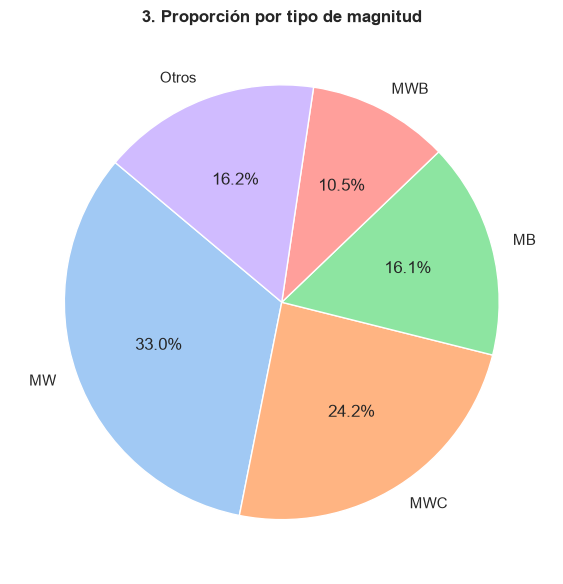

In [ ]:
# --- GRÁFICO 3: Gráfico de Pie (Torta) ---

conteo = df['Magnitude Type'].value_counts()
pie_data = pd.concat([conteo.head(4), pd.Series({'Otros': conteo.iloc[4:].sum()})])
plt.figure(figsize=(6, 6))
plt.pie(pie_data, labels=pie_data.index, autopct='%1.1f%%', startangle=140,
        colors=sns.color_palette('pastel'))
plt.title("3. Proporción por tipo de magnitud", fontweight='bold')
plt.tight_layout()
plt.show()

### Comentario del Gráfico 3
- **Qué muestra:** La proporción de registros según `Magnitude Type`, agrupando las cuatro categorías más frecuentes y el resto en “Otros”.
- **Qué patrón se observa:** Algunas convenciones de magnitud concentran una proporción importante del catálogo, mientras que varias categorías minoritarias quedan agrupadas.
- **Qué limitación presenta:** El grupo “Otros” reúne categorías heterogéneas y el gráfico de pie dificulta comparar proporciones cercanas con precisión; no muestra diferencias en calidad o incertidumbre entre escalas.

Par más correlacionado: Depth Seismic Stations vs Magnitude Seismic Stations (r = 0.81)


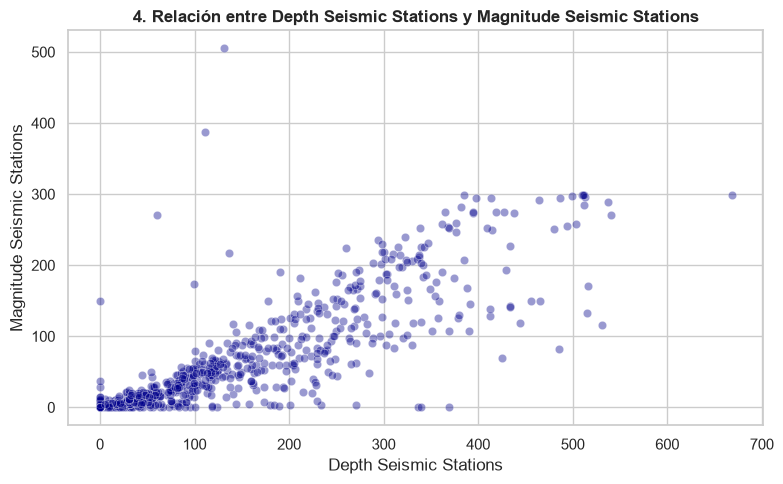

In [ ]:
# --- GRÁFICO 4: Scatter Plot (Relación entre variables) ---
num_cols = df.select_dtypes(include=[np.number]).columns.drop(['Año'], errors='ignore')
num_cols = [c for c in num_cols if not c.endswith(('_minmax', '_standard', '_label'))]
corr = df[num_cols].corr().abs().to_numpy(copy=True)
np.fill_diagonal(corr, 0)
i, j = np.unravel_index(np.nanargmax(corr), corr.shape)
v1, v2 = num_cols[i], num_cols[j]
print(f"Par más correlacionado: {v1} vs {v2} (r = {df[v1].corr(df[v2]):.2f})")

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=v1, y=v2, alpha=0.4, color='darkblue')
plt.title(f"4. Relación entre {v1} y {v2}", fontweight='bold')
plt.tight_layout()
plt.show()

### Comentario del Gráfico 4
- **Qué muestra:** Un diagrama de dispersión de las dos variables numéricas que el código identifica como el par con mayor correlación absoluta.
- **Qué patrón se observa:** Se visualiza la asociación entre las variables seleccionadas; la forma y dispersión de los puntos permiten valorar si la relación es lineal, agrupada o presenta observaciones influyentes.
- **Qué limitación presenta:** Una asociación visual y un coeficiente alto no prueban causalidad; el patrón puede depender de cobertura de la red o valores extremos.

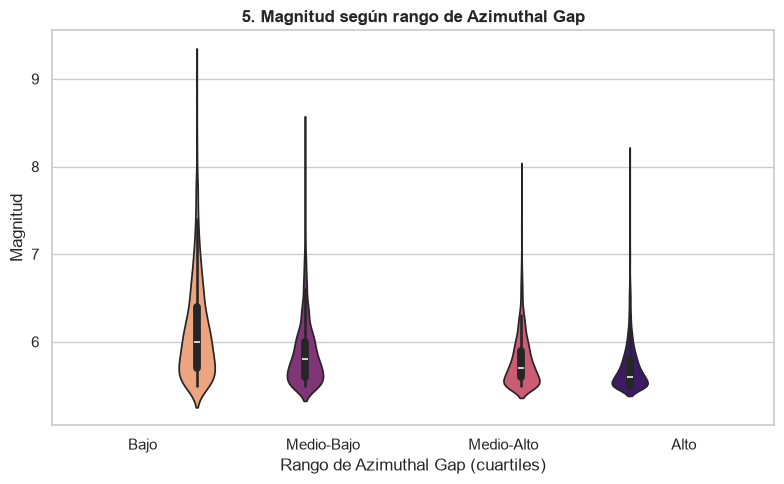

In [ ]:
# --- GRÁFICO 5: Violin Plot ---
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x='rango_Azimuthal Gap', y='Magnitude',
               hue='rango_Azimuthal Gap', palette='magma', legend=False)
plt.title("5. Magnitud según rango de Azimuthal Gap", fontweight='bold')
plt.xlabel("Rango de Azimuthal Gap (cuartiles)")
plt.ylabel("Magnitud")
plt.tight_layout()
plt.show()

### Comentario del Gráfico 5
- **Qué muestra:** Distribuciones de `Magnitude` separadas por cuartiles de `Azimuthal Gap`.
- **Qué patrón se observa:** Permite comparar medianas, dispersión y forma de la distribución de magnitudes entre niveles de separación azimutal; las distribuciones pueden solaparse ampliamente.
- **Qué limitación presenta:** La categorización en cuartiles pierde información continua de `Azimuthal Gap`, y los violines representan densidad estimada, no conteos exactos ni causalidad.

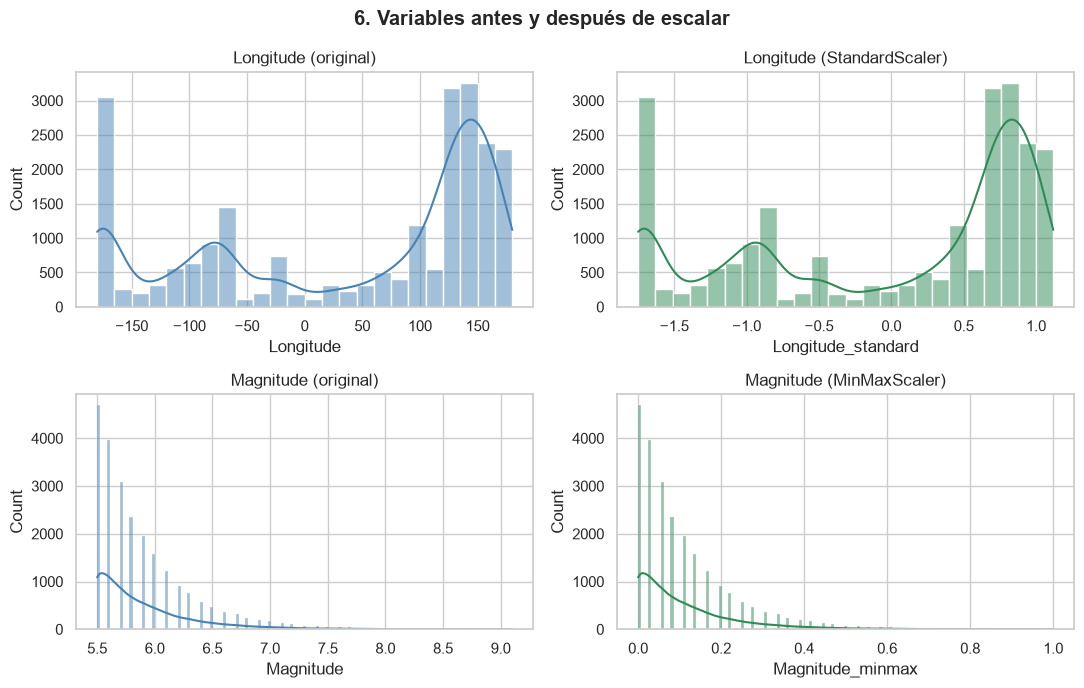

In [ ]:

# --- GRÁFICO 6: Histogramas Comparativos (Antes vs Después de Escalar) ---
df['Longitude_standard'] = StandardScaler().fit_transform(df[['Longitude']])
df['Magnitude_minmax'] = MinMaxScaler().fit_transform(df[['Magnitude']])

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
sns.histplot(df['Longitude'], kde=True, ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title("Longitude (original)")
sns.histplot(df['Longitude_standard'], kde=True, ax=axes[0, 1], color='seagreen')
axes[0, 1].set_title("Longitude (StandardScaler)")
sns.histplot(df['Magnitude'], kde=True, ax=axes[1, 0], color='steelblue')
axes[1, 0].set_title("Magnitude (original)")
sns.histplot(df['Magnitude_minmax'], kde=True, ax=axes[1, 1], color='seagreen')
axes[1, 1].set_title("Magnitude (MinMaxScaler)")
fig.suptitle("6. Variables antes y después de escalar", fontweight='bold')
plt.tight_layout()
plt.show()


### Comentario del Gráfico 6
- **Qué muestra:** Histogramas de `Longitude` antes y después de `StandardScaler`, y de `Magnitude` antes y después de `MinMaxScaler`.
- **Qué patrón se observa:** El escalamiento modifica unidades y rango, no la información de orden ni la forma general de las distribuciones; `Magnitude_minmax` queda en rango 0–1 y `Longitude_standard` se expresa en puntuaciones z.
- **Qué limitación presenta:** Los histogramas no evalúan si el escalamiento es útil para un modelo; además, `Longitude` es circular y su estandarización lineal no representa adecuadamente la continuidad alrededor del meridiano ±180°.

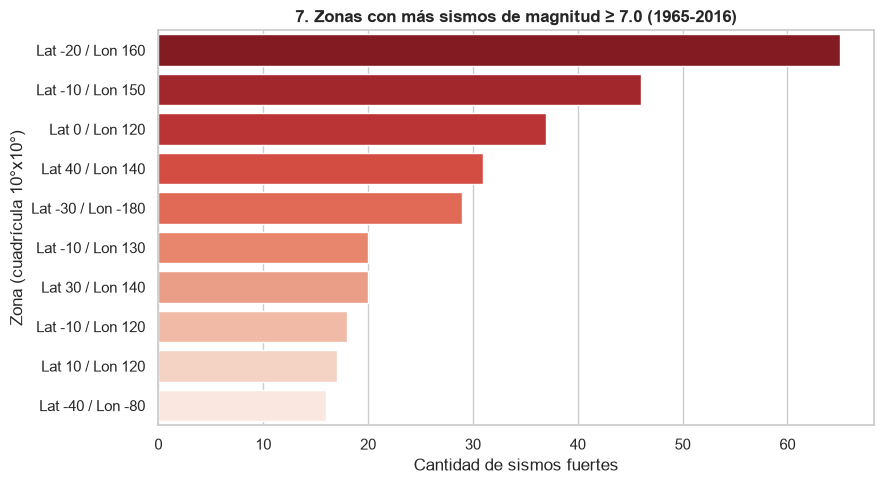


=== TOP 10 ZONAS CON SISMOS MÁS FUERTES ===
Zona
Lat -20 / Lon 160     65
Lat -10 / Lon 150     46
Lat 0 / Lon 120       37
Lat 40 / Lon 140      31
Lat -30 / Lon -180    29
Lat -10 / Lon 130     20
Lat 30 / Lon 140      20
Lat -10 / Lon 120     18
Lat 10 / Lon 120      17
Lat -40 / Lon -80     16
Name: count, dtype: int64


In [ ]:
# --- GRÁFICO 7: Tendencia Temporal (o Combinado Alternativo) ---
top_zonas = fuertes['Zona'].value_counts().head(10)
plt.figure(figsize=(9, 5))
sns.barplot(x=top_zonas.values, y=top_zonas.index, hue=top_zonas.index,
            palette='Reds_r', legend=False)
plt.title("7. Zonas con más sismos de magnitud ≥ 7.0 (1965-2016)", fontweight='bold')
plt.xlabel("Cantidad de sismos fuertes")
plt.ylabel("Zona (cuadrícula 10°x10°)")
plt.tight_layout()
plt.show()
print("\n=== TOP 10 ZONAS CON SISMOS MÁS FUERTES ===")
print(top_zonas)

### Comentario del Gráfico 7
- **Qué muestra:** Las diez cuadrículas de 10° × 10° con mayor número de sismos de magnitud ≥ 7,0, construidas a partir de latitud y longitud.
- **Qué patrón se observa:** La zona `Lat -20 / Lon 160` encabeza el conteo con **65 eventos**, seguida por `Lat -10 / Lon 150` (46) y `Lat 0 / Lon 120` (37). La concentración se ubica principalmente en cuadrículas del Pacífico occidental, según el esquema de coordenadas usado.
- **Qué limitación presenta:** Las celdas son áreas geométricas aproximadas y no corresponden a países ni límites tectónicos; además, el top 10 omite el resto de zonas y el conteo depende de la cobertura del catálogo.

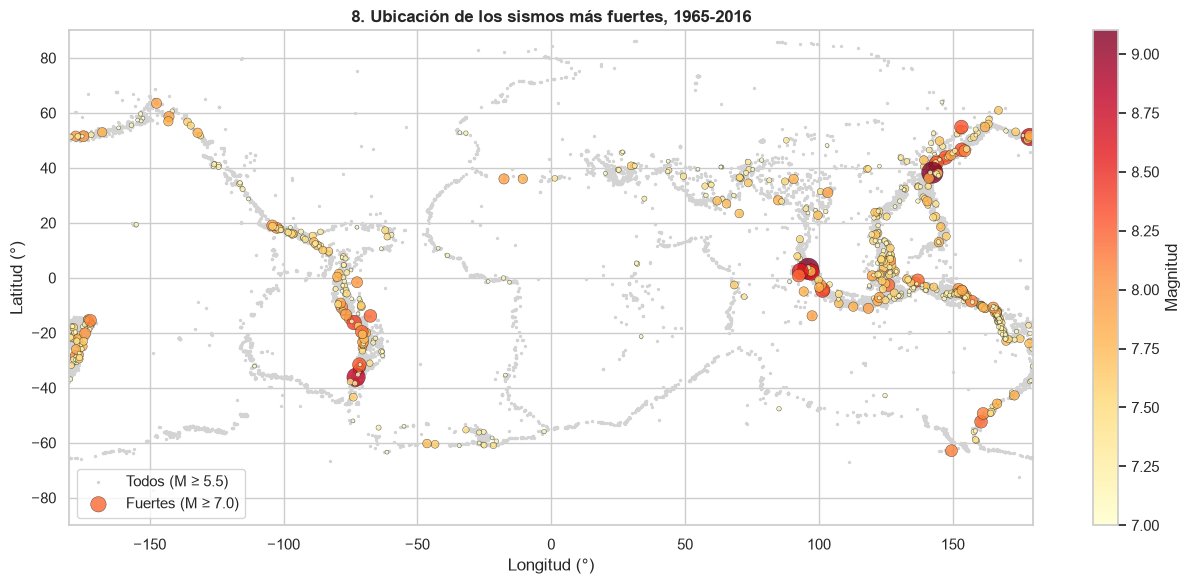

In [ ]:
# --- GRÁFICO 8: Gráfico Combinado Avanzado (Multidimensional) ---
plt.figure(figsize=(13, 6))
plt.scatter(df['Longitude'], df['Latitude'], s=2, color='lightgray', label='Todos (M ≥ 5.5)')
sc = plt.scatter(fuertes['Longitude'], fuertes['Latitude'],
                 c=fuertes['Magnitude'], s=(fuertes['Magnitude'] - 6) ** 3 * 8,
                 cmap='YlOrRd', edgecolor='k', linewidth=0.3, alpha=0.8,
                 label='Fuertes (M ≥ 7.0)')
plt.colorbar(sc, label='Magnitud')
plt.title("8. Ubicación de los sismos más fuertes, 1965-2016", fontweight='bold')
plt.xlabel("Longitud (°)")
plt.ylabel("Latitud (°)")
plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

### Comentario del Gráfico 8
- **Qué muestra:** Distribución espacial de todos los eventos del catálogo y superposición de los sismos de magnitud ≥ 7,0, con color y tamaño vinculados a su magnitud.
- **Qué patrón se observa:** Los eventos fuertes aparecen concentrados en determinadas franjas y zonas del globo, en lugar de distribuirse uniformemente; la visualización complementa el conteo de zonas del gráfico 7.
- **Qué limitación presenta:** La superposición de puntos puede ocultar eventos y el gráfico no representa densidad ajustada por exposición, población, cobertura de estaciones ni límites de placas tectónicas.

# **Reflexión Crítica sobre el Gráfico de Pie (Markdown)**

Explicar las limitaciones científicas del gráfico de torta: ¿Por qué la percepción humana de ángulos y áreas es imprecisa? ¿En qué casos está contraindicado su uso (ej. más de 5 categorías o porcentajes muy similares)?


Podemos tener en cuenta que la percepción del ojo humano y áreas es algo erróneo, pero si es más preciso comparar longitudes. Por otro lado, él gráfica de Pie no es tan apropiada con más de 5 categorías, con proporciones muy parecidas como por ejemplo 20% - 22% o cuando una categoría domina casi todo, ya que las demás rebanadas ni se distinguen. 

# **Ejercicio IA Parte 3: Error por Criterio Incorrecto en Violin Plot**

**Instrucción:** Ingrese el siguiente prompt a la IA de forma literal:

  "Genera código Python con seaborn para hacer un gráfico de violín comparando la distribución de [tu variable numérica continua] agrupada por [tu variable categórica]. Quiero que el gráfico sea lo MÁS SIMPLE POSIBLE, sin decoraciones adicionales."

**Documentación en Markdown:**

1.  **Salida recibida de la IA:** Prompt ejecutado de forma literal, con las variables del dataset: *"Genera código Python con seaborn para hacer un gráfico de violín comparando la distribución de Magnitude agrupada por rango_Latitude. Quiero que el gráfico sea lo MÁS SIMPLE POSIBLE, sin decoraciones adicionales."* (`Magnitude` es la variable continua de interés del dataset y `rango_Latitude` es la variable categórica creada en la sección 2.1). Código devuelto por la IA, que se ejecuta en la celda siguiente para obtener la imagen resultante:

```python
import seaborn as sns
import matplotlib.pyplot as plt

sns.violinplot(data=df, x='rango_Latitude', y='Magnitude')
plt.show()

```

2.  **Deficiencias Técnicas:** Identifique los elementos esenciales omitidos por la IA (título, etiquetas explícitas de ejes, unidades, leyenda, paleta adecuada).

    **Respuesta:** Elementos esenciales omitidos por la IA:

    *   **Título:** no indica la variable, la agrupación, la fuente ni el periodo.
    *   **Ejes:** usan los nombres crudos de las columnas (`rango_Latitude`, `Magnitude`), sin unidades (la magnitud es adimensional) y sin indicar a cuántos grados corresponde cada rango.
    *   **Categorías:** el orden no está controlado y no se informa el tamaño de muestra por grupo ($n = 5\,853$ en cada cuartil).
    *   **Paleta:** colores por defecto sin propósito, sin relación con el orden de los rangos.
    *   **Densidad fuera de rango:** con el valor por defecto `cut=2`, el violín se extiende por debajo de $5,5$ y por encima de $9,1$, valores que no existen en un dataset truncado en $M \geq 5{,}5$.
    *   **Leyenda y elementos internos:** no hay nota que explique la caja interna ni la fuente. La leyenda no es necesaria porque la categoría ya está en el eje X, pero la omisión no está justificada.

3.  **Rediseño del Prompt:** ¿Por qué la instrucción "lo más simple posible" indujo un error en la calidad científica del gráfico?

    **Respuesta:** La IA interpretó "lo más simple posible, sin decoraciones" como eliminar todo lo que no fuera la llamada mínima a `sns.violinplot`. Confundió la simplicidad del código con la simplicidad del gráfico y trató el título, las etiquetas con unidades, el orden y la paleta como "decoración", cuando son elementos esenciales para que la figura sea interpretable y reproducible. El prompt no definía criterios de calidad, por lo que la IA optimizó la única restricción explícita (la brevedad). Un prompt para un gráfico científico debe enunciar los requisitos como restricciones verificables.

4.  **Prompt Mejorado y Código Final:** Escriba el prompt corregido que solicita todos los requisitos visuales de publicación y presente el gráfico final obtenido.

    **Prompt mejorado:** *"Genera código Python con seaborn (versión 0.13 o superior) para un gráfico de violín de calidad científica que compare la distribución de `Magnitude` (continua, adimensional, rango 5,5 a 9,1) agrupada por `rango_Latitude` (4 categorías ordinales: Bajo, Medio-Bajo, Medio-Alto, Alto). Requisitos: (1) título descriptivo con la fuente y el periodo; (2) etiquetas de ejes explícitas con unidades; (3) orden lógico de las categorías, con el rango real de latitud y el n de cada grupo en las etiquetas; (4) paleta secuencial perceptualmente uniforme y apta para daltonismo, sin leyenda redundante; (5) `inner='quartile'` para mostrar Q1, mediana y Q3; (6) `cut=0` para que la densidad no se extienda fuera del rango observado; (7) cuadrícula suave, tamaño y resolución adecuados para publicación y una nota al pie que explique los elementos del gráfico."*

    **Código final y figura final:** se generan en la celda de código siguiente.



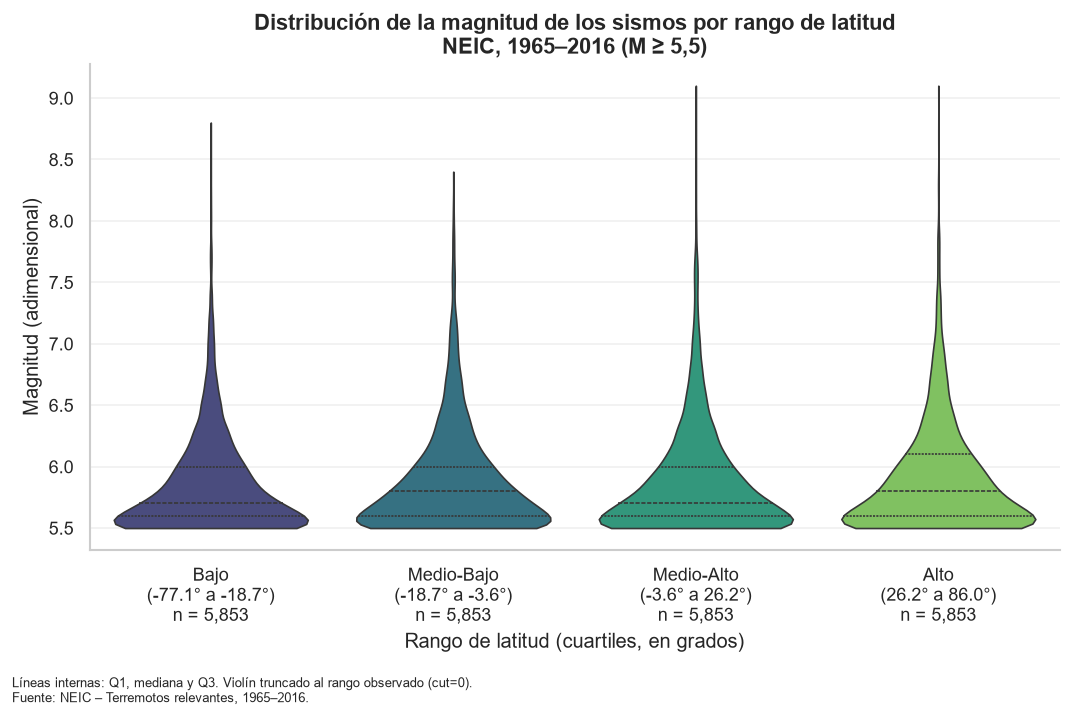

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
orden = ['Bajo', 'Medio-Bajo', 'Medio-Alto', 'Alto']

# Crear la columna que falta: cuartiles de Latitude
df['rango_Latitude'] = pd.qcut(df['Latitude'], q=4, labels=orden)


# Etiquetas con el rango real de latitud (en grados) y el tamaño de muestra de cada grupo
resumen = df.groupby('rango_Latitude', observed=True)['Latitude'].agg(['min', 'max', 'count'])
etiquetas = {
    c: f"{c}\n({resumen.loc[c, 'min']:.1f}° a {resumen.loc[c, 'max']:.1f}°)\nn = {int(resumen.loc[c, 'count']):,}"
    for c in orden
}
df_v = df.assign(grupo=df['rango_Latitude'].astype(str).map(etiquetas))
orden_etiquetas = [etiquetas[c] for c in orden]

fig, ax = plt.subplots(figsize=(9, 6), dpi=120)
sns.violinplot(
    data=df_v, x='grupo', y='Magnitude',
    order=orden_etiquetas, hue='grupo', hue_order=orden_etiquetas,
    palette='viridis', legend=False,      # paleta secuencial, apta para daltonismo
    inner='quartile',                     # Q1, mediana y Q3
    cut=0,                                # no extender la densidad fuera del rango observado
    linewidth=1, ax=ax
)
ax.set_title('Distribución de la magnitud de los sismos por rango de latitud\nNEIC, 1965–2016 (M ≥ 5,5)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Rango de latitud (cuartiles, en grados)')
ax.set_ylabel('Magnitud (adimensional)')
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
sns.despine(ax=ax)
fig.text(0.01, 0.005,
         'Líneas internas: Q1, mediana y Q3. Violín truncado al rango observado (cut=0).\n'
         'Fuente: NEIC – Terremotos relevantes, 1965–2016.',
         fontsize=8, ha='left', va='bottom')
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show() 

**Bitácora de IA - Parte 3**

**¿Usaste IA en esta parte?:** Sí

*   **Prompt exacto utilizado:** "Genera código Python con seaborn para hacer un gráfico de violín comparando la distribución de Magnitude agrupada por rango_Latitude. Quiero que el gráfico sea lo MÁS SIMPLE POSIBLE, sin decoraciones adicionales." Prompt 2 (mejorado): el redactado en el punto 4 de la documentación, con los siete requisitos visuales.

*   **Resumen del output recibido:** Con el prompt literal la IA devolvió tres líneas (sns.violinplot y plt.show) sin título, etiquetas con unidades, orden de categorías ni paleta. Con el prompt mejorado generó el gráfico con título, ejes con unidades, rango de latitud y n por grupo, paleta viridis, cuartiles internos y cut=0.

*   **¿Qué modificaste y por qué?:** Ajusté las etiquetas de las categorías para mostrar el rango real de latitud en grados y el n por grupo, y usé hue con legend=False para evitar la advertencia de seaborn 0.13 por usar palette sin hue.

*   **¿Qué aprendiste o qué error detectaste?:** Una instrucción de estilo ambigua ("lo más simple posible") degrada la calidad científica del gráfico: los requisitos visuales deben pedirse de forma explícita. También que los valores por defecto de seaborn (cut=2) pueden extender el violín fuera del rango real de los datos.

# **PARTE 4: Análisis Integrador & Evaluación Crítica**

**4.1 Análisis Integrador (Mínimo 120 palabras)**

**4.1 Análisis Integrador**

El EDA del catálogo NEIC de terremotos relevantes entre 1965 y 2016, compuesto por 23.412 registros de magnitud 5,5 o superior, muestra una distribución de magnitudes concentrada en valores moderados y asimétrica hacia la derecha: la media es 5,88, la mediana 5,7 y el máximo 9,1. El boxplot identifica 1.475 sismos con magnitud superior a 6,60, que constituyen observaciones extremas según el criterio IQR y son importantes para describir la cola de eventos fuertes, aunque no deben interpretarse automáticamente como una clasificación de riesgo.

La pregunta central —¿dónde se concentran los terremotos más fuertes?— se aborda mediante el agrupamiento espacial en cuadrículas de 10° × 10° de los eventos con magnitud ≥ 7,0. La cuadrícula `Lat -20 / Lon 160` concentra 65 eventos, seguida por `Lat -10 / Lon 150` con 46 y `Lat 0 / Lon 120` con 37. En el mapa y el ranking, la concentración principal se observa en sectores del Pacífico occidental. Esta aproximación permite identificar zonas geográficas de mayor frecuencia en el catálogo, sin atribuirlas a países ni límites tectónicos que el dataset no contiene.

La matriz de correlación muestra la asociación más alta entre `Depth Seismic Stations` y `Magnitude Seismic Stations` ($r = 0,81$), junto con relaciones entre variables de error de medición. Estas asociaciones pueden reflejar cobertura y calidad de observación y no prueban causalidad. Además, el catálogo está limitado a magnitudes ≥ 5,5, presenta faltantes importantes en variables de calidad y una cobertura de fuentes heterogénea; por ello, las frecuencias no equivalen a una descripción completa de la actividad sísmica mundial. El EDA cumple los objetivos descriptivos y espaciales dentro de esas limitaciones. Para profundizar, sería recomendable normalizar fechas, investigar magnitudes y profundidades extremas, evaluar la cobertura temporal y complementar las cuadrículas con límites tectónicos o geocodificación, evitando inferir riesgo sin datos de exposición y vulnerabilidad.

**4.2 Reflexión sobre el Rol de la IA (Mínimo 80 palabras)**

Responda críticamente:

*  ¿Qué tareas delegó a la IA y cuáles decidió asumir de forma autónoma?

*  ¿Cómo habría cambiado la calidad o velocidad del análisis sin herramientas de IA?

*  ¿Qué errores, sesgos o imprecisiones detectó en las respuestas de la IA durante la guía?

**Respuesta:** Delegué a la IA tareas de contraste y apoyo: verificar la interpretación de la correlación
(Parte 1), revisar el código de escalamiento 
(Parte 2), generar y luego mejorar el gráfico de violín 
(Parte 3), proponer hallazgos de contraste y actuar como evaluador 
(Parte 4). Asumí de forma autónoma la carga del dataset, el cálculo de métricas, la elección de variables y escaladores, y la decisión final sobre cada sugerencia (Acepto / Adapto / Rechazo). Sin IA el análisis habría sido más lento en la depuración y en la redacción, pero también habría tenido más puntos ciegos, como la circularidad de la longitud o el sesgo de detección de la red sísmica. Detecté imprecisiones: con el prompt "lo más simple posible" la IA entregó un gráfico sin elementos esenciales, sugirió cambiar variables que no aplicaban a la consigna y, al recibir solo un resumen, no pudo advertir problemas del propio procesamiento (como el uso de Date en las pruebas de hipótesis). Por eso sus respuestas deben verificarse contra los resultados del notebook.

**Ejercicio IA Parte 4A: Validación Cruzada de Interpretaciones**

**Paso 1:** Escriba primero en Markdown su propia interpretación de los 3 hallazgos más importantes del EDA sin usar IA (Mínimo 60 palabras).

**Mi interpretación (sin IA):**

1.  La magnitud es asimétrica a la derecha: la media ($5,88$) supera a la mediana ($5,7$) y el máximo llega a $9,1$, por lo que la mayoría de los sismos se concentra entre $5,5$ y $6,0$ y los eventos fuertes son pocos.
2.  Las correlaciones más altas ocurren entre variables de calidad de la medición ($r = 0,81$ entre `Depth Seismic Stations` y `Magnitude Seismic Stations`; $0,62$ a $0,64$ entre los errores), mientras que `Magnitude` casi no se asocia linealmente con latitud, longitud ni profundidad ($|r| \leq 0,04$).
3.  Entre el 69 % y el 99 % de los registros tienen nulos en 7 variables de calidad (por ejemplo, `Magnitude Error` con 98,6 %) y el 99,2 % de los eventos son de tipo `Earthquake`, lo que limita el análisis comparativo por tipo y por calidad de medición.

**Paso 2:** Envíe el siguiente prompt a la IA sin mostrarle su análisis personal:

"Analicé el dataset y obtuve los siguientes resultados: describe brevemente las correlaciones, outliers y diferencias de grupo más importantes. ¿Cuáles son los tres hallazgos más relevantes desde una perspectiva de análisis de datos?"

**Prompt enviado (con los resultados del EDA, sin mostrar mi interpretación):** *"Analicé el dataset Terremotos relevantes 1965–2016 (NEIC, 23 412 registros, 21 variables) y obtuve los siguientes resultados: magnitud con media 5,88, mediana 5,7, mínimo 5,5 y máximo 9,1; la correlación más alta es entre Depth Seismic Stations y Magnitude Seismic Stations (r = 0,81), seguida de Depth Error con Horizontal Error (0,64) y de Depth Error con Magnitude Error (0,62), mientras que Magnitude casi no se correlaciona con Latitude, Longitude ni Depth (|r| ≤ 0,04); entre 69 % y 99 % de nulos en 7 variables de calidad de la medición; 99,2 % de los registros son de tipo Earthquake; Depth tiene media 70,8, mediana 33 y máximo 700 km (CV = 173 %). ¿Cuáles son los tres hallazgos más relevantes desde una perspectiva de análisis de datos?"*

**Tabla Comparativa de Hallazgos:**

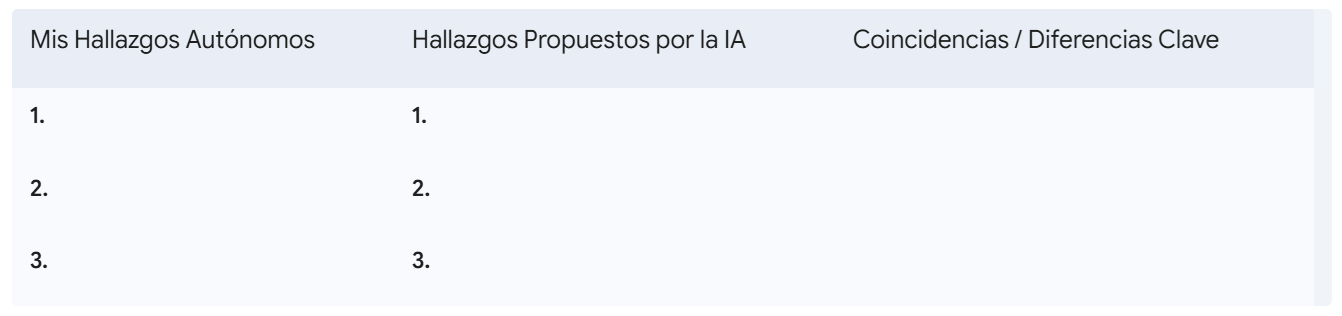

| Mis Hallazgos Autónomos | Hallazgos Propuestos por la IA | Coincidencias / Diferencias Clave |
|---|---|---|
| 1. Magnitud asimétrica a la derecha (media 5,88 > mediana 5,7; máximo 9,1). | 1. La frecuencia cae rápidamente al aumentar la magnitud, patrón coherente con la ley de Gutenberg-Richter; los eventos de magnitud alta son raros. | Coinciden en la forma de la distribución. La IA aporta el marco teórico y yo las cifras del dataset. |
| 2. Correlaciones fuertes solo entre variables de calidad (0,81; 0,64; 0,62) y Magnitude sin asociación lineal con ubicación ni profundidad. | 2. Las correlaciones altas reflejan artefactos de la red de monitoreo (número de estaciones, errores) y no fenómenos físicos; no deben leerse como causales. | Coincidencia total. La IA enfatizó el riesgo de causalidad espuria. |
| 3. Alta proporción de nulos (69 % a 99 %) en 7 variables y 99,2 % de registros Earthquake. | 3. El dataset está truncado en M ≥ 5,5 y la cobertura de la red cambió entre 1965 y 2016, lo que produce sesgo de detección y limita la comparación entre periodos. | Diferencia: yo detecté los nulos y el desbalance de Type; la IA agregó el sesgo de detección y el truncamiento, que yo no había considerado. |

*  **Reflexión:** ¿Qué aspectos identificó usted que la IA omitió? ¿Qué observaciones de la IA enriquecieron su análisis?

    **Respuesta:** La IA solo recibió un resumen, por lo que omitió problemas del propio procesamiento que identifiqué: la matriz de correlación incluye columnas derivadas del escalamiento y Date_label, la prueba t dio NaN y la chi-cuadrada se aplicó con Date como variable categórica. Tampoco priorizó la asociación moderada entre Magnitude y Depth Seismic Stations ($r = 0,44$), que podría indicar que los eventos más grandes son registrados por más estaciones. De la IA me enriquecieron el marco de la ley de Gutenberg-Richter para explicar la forma de la distribución de magnitudes y la advertencia de sesgo de detección y truncamiento, que cambia cómo deben leerse las tendencias en el tiempo.

**Ejercicio IA Parte 4B: La IA como Evaluador Crítico (Rol Adversarial)**

**Instrucción:** Someta su análisis integrador a evaluación crítica enviando el siguiente prompt:

"Actúa como evaluador académico riguroso de un trabajo de análisis exploratorio de datos de nivel especialización. Lee el siguiente análisis y señala:
-  Al menos dos debilidades metodológicas.
-  Al menos una limitación no reconocida por el autor.
-  Al menos una pregunta que el análisis deja sin responder pero debería haber respondido: [Pega tu Análisis Integrador]"

**Análisis sometido a la IA (síntesis de los resultados del EDA):** *"El dataset NEIC 1965–2016 reúne 23 412 sismos de magnitud ≥ 5,5 (media 5,88; mediana 5,7; máximo 9,1) descritos por 21 variables. La magnitud es asimétrica a la derecha y casi no se correlaciona con latitud, longitud ni profundidad (|r| ≤ 0,04). Las correlaciones más altas ocurren entre variables de calidad de la medición (r = 0,81 entre Depth Seismic Stations y Magnitude Seismic Stations; 0,62 a 0,64 entre errores) y no implican causalidad, sino cobertura de la red. Latitude no presenta outliers por IQR (0 de 23 412). La prueba chi-cuadrada entre Date y Type dio p = 1,5e-29. Entre 69 % y 99 % de varios campos de calidad son nulos y 99,2 % de los registros son Earthquake. Los hallazgos ayudan a decidir qué variables son confiables para modelar, pero el análisis es solo descriptivo."*

**Evaluación recibida de la IA:**

1.  *Debilidad metodológica:* las pruebas de hipótesis están mal planteadas. La prueba t compara dos fechas con una observación cada una (t = NaN) y la chi-cuadrada usa `Date` (12 401 categorías) con frecuencias esperadas menores a 5, lo que invalida el p-valor de 1,5e-29.
2.  *Debilidad metodológica:* los outliers solo se evaluaron en `Latitude`, variable acotada físicamente a ±90°, donde 0 outliers es esperable y poco informativo; no se evaluaron `Magnitude` ni `Depth`, que son las relevantes.
3.  *Limitación no reconocida:* sesgo de detección y cobertura heterogénea de la red sísmica (13 fuentes y registros `Automatic` frente a `Reviewed`), además del truncamiento en M ≥ 5,5, que impiden interpretar tendencias en el tiempo o comparar regiones sin ajustar.
4.  *Pregunta sin responder:* ¿dónde se concentran los sismos más fuertes? No se agregó por región ni se filtraron los eventos de mayor magnitud.

**Matriz de Respuesta al Evaluador IA:**

1. **Crítica 1 (Debilidad metodológica): Acepto la crítica.** La comparación de magnitud se corrigió para usar `Magnitude` por categorías de `Status` (Automatic y Reviewed), con Welch (`equal_var=False`) porque no se exige igualdad de varianzas. Para la Chi-cuadrada se cruza `Date` (convertida a año para evitar una categoría por fecha individual) con `Type`. Se debe revisar el conteo de frecuencias esperadas; el p-value indica asociación, no causalidad.

2. **Crítica 2 (Outliers): Acepto y amplío.** El gráfico 2 aplica el límite IQR de 6,60 y permite identificar **1.475 eventos con magnitud superior a 6,60**. Son eventos extremos en términos estadísticos dentro de este catálogo y resultan relevantes para describir la cola de magnitudes, aunque el criterio IQR no equivale a un nivel de peligro sísmico.

3. **Crítica 3 (Limitación no reconocida): Matizo.** El catálogo está truncado en magnitudes ≥ 5,5 y su cobertura no es homogénea: depende de fuentes, redes de monitoreo, procedimientos de detección y revisión. Por ello, las frecuencias históricas no deben interpretarse como una medida completa de la ocurrencia de todos los sismos.

4. **Crítica 4 (Pregunta central): Acepto y respondo con el análisis espacial.** La concentración se examina mediante cuadrículas de 10° × 10° para los eventos de magnitud ≥ 7,0. La celda con mayor conteo es `Lat -20 / Lon 160` (65 sismos), seguida por `Lat -10 / Lon 150` (46) y `Lat 0 / Lon 120` (37). Esto señala una concentración de eventos fuertes en el Pacífico occidental dentro de la discretización usada. La agregación por cuadrícula no permite asignar directamente los conteos a países o placas tectónicas, pero sí ofrece una respuesta espacial reproducible a la pregunta central.

**Bitácora de IA - Parte 4**

*   **¿Usaste IA en esta parte?:** Sí

*   **Prompt exacto utilizado:** "Analicé el dataset Terremotos relevantes 1965–2016 (NEIC, 23 412 registros, 21 variables) y obtuve los siguientes resultados: [resumen de magnitud, correlaciones, nulos, tipo de evento y profundidad]. ¿Cuáles son los tres hallazgos más relevantes desde una perspectiva de análisis de datos?" 
"Actúa como evaluador académico riguroso de un trabajo de análisis exploratorio de datos de nivel especialización. Lee el siguiente análisis y señala: 1) Al menos dos debilidades metodológicas. 2) Al menos una limitación no reconocida por el autor. 3) Al menos una pregunta que el análisis deja sin responder pero debería haber respondido: [síntesis del análisis integrador]"

*   **Resumen del output recibido:** la IA propuso tres hallazgos: distribución de magnitudes coherente con la ley de Gutenberg-Richter, correlaciones altas que reflejan artefactos de la red de monitoreo, y sesgo de detección y truncamiento del dataset. 4B: devolvió cuatro críticas: pruebas de hipótesis inválidas (uso de Date), outliers evaluados solo en Latitude, heterogeneidad de fuentes y sesgo de detección no reconocidos, y pregunta central sin responder (dónde se concentran los sismos más fuertes).

*   **¿Qué modificaste y por qué?:** Acepté tres críticas y maticé una, contrastando cada una con los resultados del notebook en lugar de aceptarlas automáticamente. No modifiqué el análisis original; registré como correcciones y propuestas: usar Status frente a Magnitude en la prueba t, aplicar IQR a Magnitude y Depth, y agregar un análisis por región.

*   **¿Qué aprendiste o qué error detectaste?:** Como evaluador adversarial detecta errores metodológicos que había pasado por alto (la prueba de hipótesis sobre Date, que no tenía sentido), pero sus críticas deben verificarse contra los datos. También que un resumen incompleto limita lo que la IA puede evaluar.

#**REFERENCIAS BIBLIOGRÁFICAS**
<p style="padding-left: 2em; text-indent: -2em;">
    McKinney, W. (2022).  Python for data analysis: Data wrangling with pandas, NumPy, and Jupyter (3rd ed.) O'Reilly Media. https://wesmckinney.com/book/
</p>
<p style="padding-left: 2em; text-indent: -2em;">
    McKinney, W. (2022).  Python for data analysis: Data wrangling with pandas, NumPy, and Jupyter (3rd ed.) O'Reilly Media. https://wesmckinney.com/book/
</p>
<p style="padding-left: 2em; text-indent: -2em;">
    VanderPlas, J. (2016).  Python data science handbook: Essential tools for working with data O'Reilly Media. https://jakevdp.github.io/PythonDataScienceHandbook/
</p>
<p style="padding-left: 2em; text-indent: -2em;">
    VanderPlas, J. (2016).  Python data science handbook: Essential tools for working with data O'Reilly Media. https://jakevdp.github.io/PythonDataScienceHandbook/
</p>
<p style="padding-left: 2em; text-indent: -2em;">
    Noguera Torres, A. del P., Niño Mojica, M. D., & Carreño Rios, C. A. (2024).  Análisis del rendimiento académico de estudiantes de ingeniería electrónica de la UNAD . La Tuerka. https://doi-org.bibliotecavirtual.unad.edu.co/10.22490/30730260.8507
</p>


